In [5]:
!pip install medpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.3/156.3 kB 4.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for medpy: filename=MedPy-0.5.2-py3-none-any.whl size=224710 sha256=794c04c856a2d790c8da5ddc64a96d2934ecb461874b6908d87c0a333914bd5b
  Stored in directory: /root/.cache/pip/wheels/89/5a/f8/b3def53b9c2133d2f8698ea2173bb5df63bd8e761ce8e9aec9
Successfully built medpy


In [6]:
# ========================================================================
# FINAL FULL VERSION: VNet3D | 100 EPOCHS | LR 1e-4 | FULL LOGGING & TIME
# ========================================================================
import os, random, csv, time
from pathlib import Path
import numpy as np
import nibabel as nib
import scipy.ndimage as ndi
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from medpy.metric.binary import dc, jc, hd95 

# ---------------- 0. CONFIGURATION ----------------
ROOT_DIR = Path("/kaggle/input/m-and-ms-challenge/MnM2/dataset")
SAVE_DIR = Path("./vnet3d_final_results")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

TARGET_SIZE = (128, 128, 64)
NUM_CLASSES = 4
BATCH_SIZE = 4 
EPOCHS = 100 
LR = 1e-4  
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---------------- 1. LOSS FUNCTIONS ----------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super(DiceLoss, self).__init__()
        self.smooth = smooth
    def forward(self, pred, target):
        pred = F.softmax(pred, dim=1)
        target_oh = F.one_hot(target, num_classes=NUM_CLASSES).permute(0, 4, 1, 2, 3).float()
        dims = (0, 2, 3, 4)
        intersection = torch.sum(pred[:, 1:] * target_oh[:, 1:], dims)
        cardinality = torch.sum(pred[:, 1:] + target_oh[:, 1:], dims)
        return 1 - ((2. * intersection + self.smooth) / (cardinality + self.smooth)).mean()

# ---------------- 2. ARCHITECTURE (VNet3D) ----------------
class ShortCutConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Identity() if in_ch == out_ch else nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, bias=False), nn.InstanceNorm3d(out_ch))
    def forward(self, x): return self.conv(x)

class VBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = nn.Conv3d(in_ch, out_ch, 5, padding=2, bias=False)
        self.in1 = nn.InstanceNorm3d(out_ch); self.prelu1 = nn.PReLU(out_ch)
        self.conv2 = nn.Conv3d(out_ch, out_ch, 5, padding=2, bias=False)
        self.in2 = nn.InstanceNorm3d(out_ch); self.prelu2 = nn.PReLU(out_ch)
        self.short = ShortCutConv3D(in_ch, out_ch)
    def forward(self, x):
        sc = self.short(x)
        out = self.prelu2(self.in2(self.conv2(self.prelu1(self.in1(self.conv1(x))))))
        return out + sc

class VNet3D(nn.Module):
    def __init__(self, num_classes=4, f=16):
        super().__init__()
        self.enc1 = VBlock(1, f); self.down1 = nn.Conv3d(f, 2*f, 2, stride=2) 
        self.enc2 = VBlock(2*f, 2*f); self.down2 = nn.Conv3d(2*f, 4*f, 2, stride=2)
        self.enc3 = VBlock(4*f, 4*f); self.down3 = nn.Conv3d(4*f, 8*f, 2, stride=2)
        self.bottleneck = VBlock(8*f, 8*f)
        self.up3 = nn.ConvTranspose3d(8*f, 8*f, 2, stride=2); self.dec3 = VBlock(12*f, 4*f) 
        self.up2 = nn.ConvTranspose3d(4*f, 4*f, 2, stride=2); self.dec2 = VBlock(6*f, 2*f)  
        self.up1 = nn.ConvTranspose3d(2*f, 2*f, 2, stride=2); self.dec1 = VBlock(3*f, f)    
        self.final = nn.Conv3d(f, num_classes, 1)
    def forward(self, x):
        x1 = self.enc1(x); x2 = self.enc2(self.down1(x1)); x3 = self.enc3(self.down2(x2))
        b = self.bottleneck(self.down3(x3))
        d3 = self.dec3(torch.cat([self.up3(b), x3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), x2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), x1], 1))
        return self.final(d1)

# ---------------- 3. DATASET & METRICS ----------------
class VolumeDataset(Dataset):
    def __init__(self, items, augment=False):
        self.items = items; self.augment = augment
    def __len__(self): return len(self.items)
    def __getitem__(self, idx):
        img_p, gt_p = self.items[idx]
        img = nib.load(img_p).get_fdata().astype(np.float32)
        gt = nib.load(gt_p).get_fdata().astype(np.int64)
        zoom = (TARGET_SIZE[0]/img.shape[0], TARGET_SIZE[1]/img.shape[1], TARGET_SIZE[2]/img.shape[2])
        img = ndi.zoom(img, zoom, order=1); gt = ndi.zoom(gt, zoom, order=0)
        if self.augment: you 
            if random.random() > 0.5:
                ax = random.randint(0, 2)
                img, gt = np.flip(img, ax).copy(), np.flip(gt, ax).copy()
            if random.random() > 0.3:
                angle = random.uniform(-10, 10)
                img = ndi.rotate(img, angle, axes=(0, 1), reshape=False, order=1)
                gt = ndi.rotate(gt, angle, axes=(0, 1), reshape=False, order=0)
        img = (img - img.mean()) / (img.std() + 1e-6)
        return {"image": torch.from_numpy(img[None]).float(), "label": torch.from_numpy(gt).long()}

def get_metrics(p, g):
    res = {}
    for cl, name in zip([1, 2, 3], ['LV', 'RV', 'MYO']):
        pc, gc = (p==cl).astype(np.uint8), (g==cl).astype(np.uint8)
        if gc.sum() == 0: res[name] = (0.0, 0.0, 50.0); continue
        res[name] = (dc(pc, gc), jc(pc, gc), hd95(pc, gc) if pc.sum()>0 else 50.0)
    return res

# ---------------- 4. PREPARE DATA ----------------
items = []
for p in sorted(ROOT_DIR.iterdir()):
    if not p.is_dir(): continue
    for s in ["ED", "ES"]:
        img, gt = p/f"{p.name}_SA_{s}.nii", p/f"{p.name}_SA_{s}_gt.nii"
        if img.exists() and gt.exists(): items.append((str(img), str(gt)))

tr_items, temp_items = train_test_split(items, test_size=0.3, random_state=SEED)
va_items, te_items = train_test_split(temp_items, test_size=0.5, random_state=SEED)

loaders = {
    'train': DataLoader(VolumeDataset(tr_items, True), BATCH_SIZE, shuffle=True),
    'val': DataLoader(VolumeDataset(va_items), 1)
}

# ---------------- 5. TRAINING INITIALIZATION ----------------
model = VNet3D().to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'max', patience=10, factor=0.5)

ce_criterion = nn.CrossEntropyLoss()
dice_criterion = DiceLoss()
scaler = torch.amp.GradScaler('cuda')
best_dice = 0

# CSV Initialization with 'time' column
CSV_PATH = SAVE_DIR / "training_log.csv"
with open(CSV_PATH, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['epoch', 'tr_loss', 'va_loss', 'tr_dice', 'va_dice', 'va_iou', 'va_hd95', 'lv_d', 'rv_d', 'myo_d', 'time'])

print(f"Training VNet3D | Train: {len(tr_items)} | Val: {len(va_items)} | Test: {len(te_items)}")
print("-" * 170)

# ---------------- 6. MAIN LOOP ----------------
for ep in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    tr_l, tr_d_list = [], []
    
    for b in tqdm(loaders['train'], desc=f"Epoch {ep:02d}", leave=False, bar_format='{l_bar}{bar:10}{r_bar}'):
        img, lab = b["image"].to(DEVICE), b["label"].to(DEVICE)
        optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            out = model(img)
            loss = ce_criterion(out, lab) + dice_criterion(out, lab)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        tr_l.append(loss.item())
        tr_d_list.append(dc(torch.argmax(out,1).cpu().numpy()>0, lab.cpu().numpy()>0))

    model.eval()
    va_l, metrics_acc = [], {'LV':[], 'RV':[], 'MYO':[]}
    with torch.no_grad():
        for b in loaders['val']:
            img, lab = b["image"].to(DEVICE), b["label"].to(DEVICE)
            out = model(img)
            va_l.append((ce_criterion(out, lab) + dice_criterion(out, lab)).item())
            p, g = torch.argmax(out, 1).cpu().numpy()[0], lab.cpu().numpy()[0]
            m = get_metrics(p, g)
            for n in ['LV', 'RV', 'MYO']: metrics_acc[n].append(m[n])

    avg_tr_loss, avg_va_loss, avg_tr_dice = np.mean(tr_l), np.mean(va_l), np.mean(tr_d_list)
    stats = {n: np.mean(metrics_acc[n], 0) for n in ['LV', 'RV', 'MYO']}
    avg_va_dice = np.mean([stats[n][0] for n in ['LV', 'RV', 'MYO']])
    avg_va_iou  = np.mean([stats[n][1] for n in ['LV', 'RV', 'MYO']])
    avg_va_hd95 = np.mean([stats[n][2] for n in ['LV', 'RV', 'MYO']])
    
    scheduler.step(avg_va_dice)
    t_total = time.time() - t0

    # Print LOG formatted exactly as requested
    log_str = f"Ep {ep:02d} | {t_total:5.1f}s | Tr.Loss: {avg_tr_loss:.4f} | Va.Loss: {avg_va_loss:.4f} | Tr.Dice: {avg_tr_dice:.4f} | "
    log_str += f"Va.Dice: {avg_va_dice:.4f} | IoU: {avg_va_iou:.4f} | HD95: {avg_va_hd95:.2f} | "
    log_str += f"LV(D/I/H): {stats['LV'][0]:.3f}/{stats['LV'][1]:.3f}/{stats['LV'][2]:.1f} | "
    log_str += f"MYO(D/I/H): {stats['MYO'][0]:.3f}/{stats['MYO'][1]:.3f}/{stats['MYO'][2]:.1f} | "
    log_str += f"RV(D/I/H): {stats['RV'][0]:.3f}/{stats['RV'][1]:.3f}/{stats['RV'][2]:.1f}"
    print(log_str)

    # Save to CSV including time
    with open(CSV_PATH, 'a', newline='') as f:
        csv.writer(f).writerow([ep, avg_tr_loss, avg_va_loss, avg_tr_dice, avg_va_dice, avg_va_iou, avg_va_hd95, 
                               stats['LV'][0], stats['RV'][0], stats['MYO'][0], t_total])

    if avg_va_dice > best_dice:
        best_dice = avg_va_dice
        torch.save(model.state_dict(), SAVE_DIR / "best_model.pth")
        print(f"🌟 New Best Model Saved (Dice: {best_dice:.4f})")

Training VNet3D | Train: 504 | Val: 108 | Test: 108
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


Ep 01 | 456.6s | Tr.Loss: 2.0343 | Va.Loss: 1.8717 | Tr.Dice: 0.2688 | Va.Dice: 0.4083 | IoU: 0.2866 | HD95: 41.01 | LV(D/I/H): 0.614/0.466/35.7 | MYO(D/I/H): 0.420/0.284/32.1 | RV(D/I/H): 0.192/0.110/55.3
🌟 New Best Model Saved (Dice: 0.4083)


Ep 02 | 378.7s | Tr.Loss: 1.7943 | Va.Loss: 1.7151 | Tr.Dice: 0.5579 | Va.Dice: 0.5321 | IoU: 0.3924 | HD95: 19.39 | LV(D/I/H): 0.701/0.560/12.5 | MYO(D/I/H): 0.530/0.383/14.1 | RV(D/I/H): 0.365/0.234/31.6
🌟 New Best Model Saved (Dice: 0.5321)


Ep 03 | 379.8s | Tr.Loss: 1.6625 | Va.Loss: 1.6155 | Tr.Dice: 0.6583 | Va.Dice: 0.5994 | IoU: 0.4485 | HD95: 20.50 | LV(D/I/H): 0.691/0.544/26.0 | MYO(D/I/H): 0.644/0.492/12.4 | RV(D/I/H): 0.463/0.310/23.1
🌟 New Best Model Saved (Dice: 0.5994)


Ep 04 | 379.3s | Tr.Loss: 1.5471 | Va.Loss: 1.4828 | Tr.Dice: 0.7138 | Va.Dice: 0.6198 | IoU: 0.4762 | HD95: 12.09 | LV(D/I/H): 0.764/0.635/12.5 | MYO(D/I/H): 0.619/0.468/11.8 | RV(D/I/H): 0.477/0.325/12.0
🌟 New Best Model Saved (Dice: 0.6198)


Ep 05 | 371.1s | Tr.Loss: 1.4395 | Va.Loss: 1.3837 | Tr.Dice: 0.7519 | Va.Dice: 0.6784 | IoU: 0.5322 | HD95: 9.93 | LV(D/I/H): 0.798/0.673/7.3 | MYO(D/I/H): 0.653/0.504/14.8 | RV(D/I/H): 0.584/0.419/7.6
🌟 New Best Model Saved (Dice: 0.6784)


... (91 outputs left out)

Ep 97 | 379.6s | Tr.Loss: 0.1101 | Va.Loss: 0.1541 | Tr.Dice: 0.9580 | Va.Dice: 0.8830 | IoU: 0.7971 | HD95: 2.06 | LV(D/I/H): 0.928/0.868/1.9 | MYO(D/I/H): 0.887/0.805/2.9 | RV(D/I/H): 0.834/0.718/1.4


Ep 98 | 382.4s | Tr.Loss: 0.1110 | Va.Loss: 0.1582 | Tr.Dice: 0.9576 | Va.Dice: 0.8791 | IoU: 0.7904 | HD95: 2.07 | LV(D/I/H): 0.926/0.865/2.0 | MYO(D/I/H): 0.877/0.787/2.8 | RV(D/I/H): 0.835/0.719/1.4


Ep 99 | 385.9s | Tr.Loss: 0.1080 | Va.Loss: 0.1513 | Tr.Dice: 0.9591 | Va.Dice: 0.8831 | IoU: 0.7967 | HD95: 1.92 | LV(D/I/H): 0.925/0.864/1.9 | MYO(D/I/H): 0.893/0.812/2.5 | RV(D/I/H): 0.831/0.714/1.3


Ep 100 | 385.6s | Tr.Loss: 0.1052 | Va.Loss: 0.1517 | Tr.Dice: 0.9605 | Va.Dice: 0.8835 | IoU: 0.7972 | HD95: 2.02 | LV(D/I/H): 0.925/0.864/2.0 | MYO(D/I/H): 0.892/0.811/2.7 | RV(D/I/H): 0.833/0.717/1.3


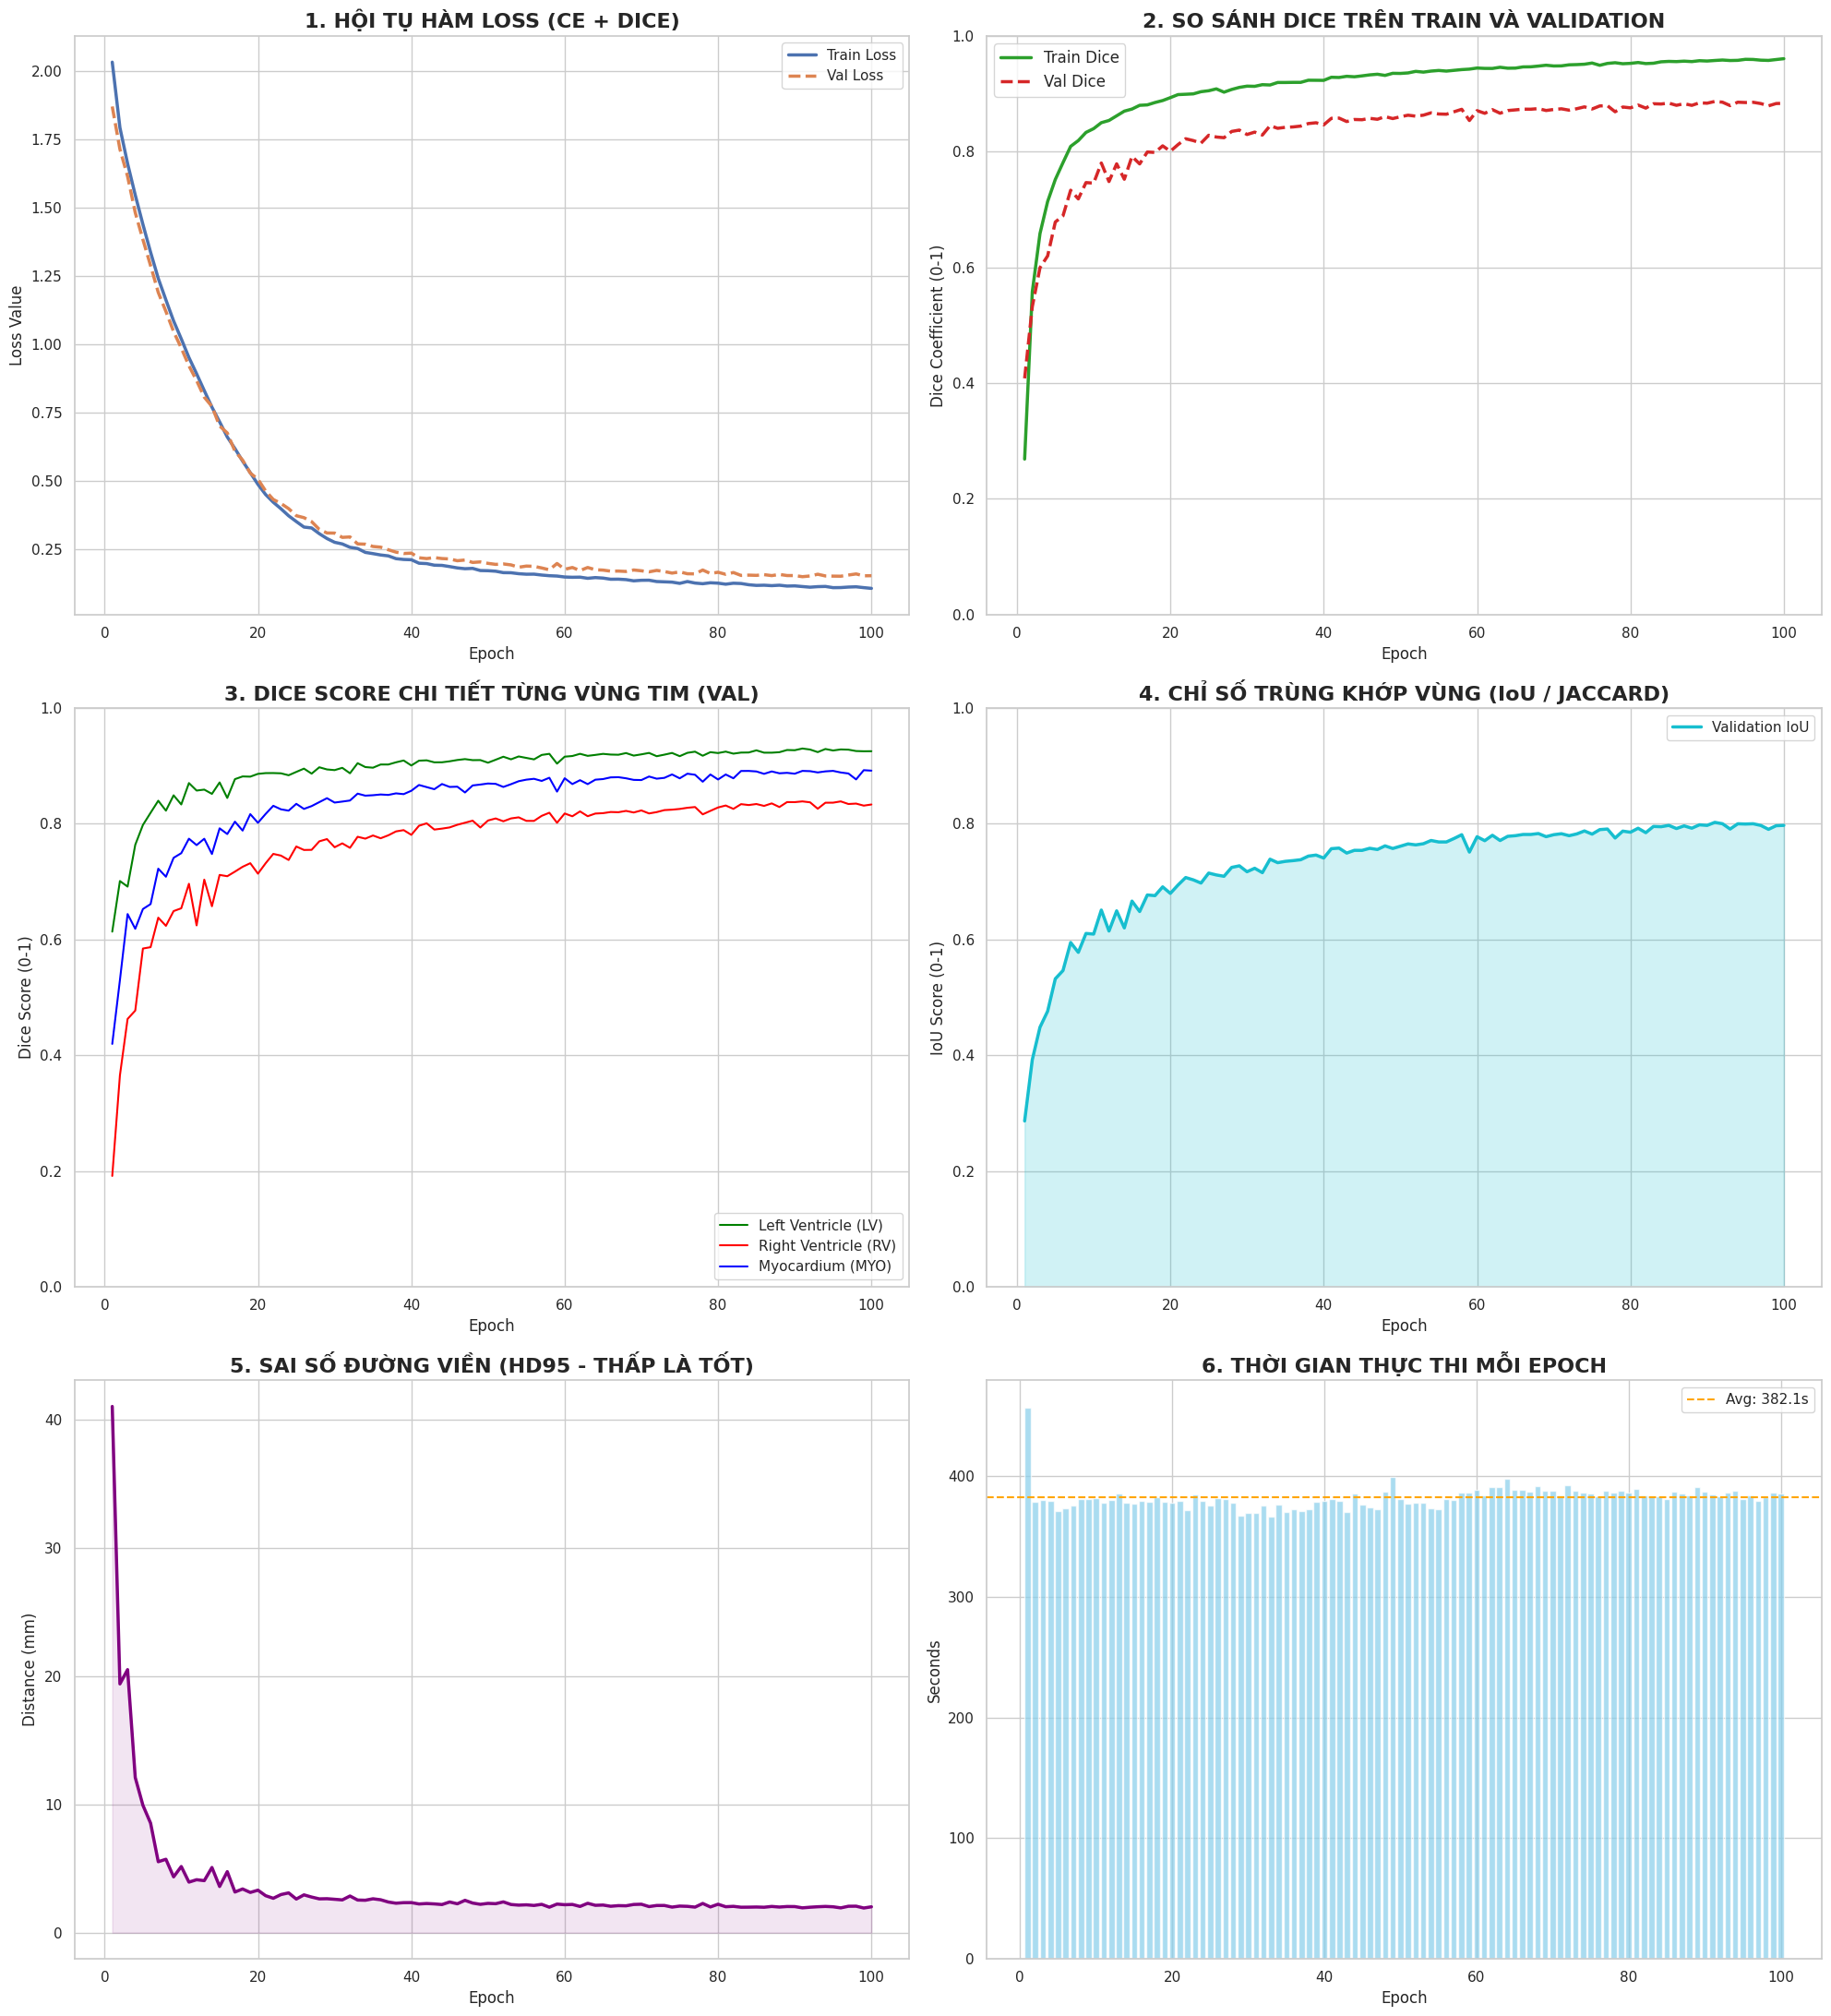


         BÁO CÁO SỐ LIỆU ĐỊNH LƯỢNG MÔ HÌNH VNET3D          
KẾT QUẢ TẠI EPOCH TỐT NHẤT (BEST EPOCH: 91)
  > Dice Score (Overall)      :     0.8867
  > IoU (Jaccard Index)       :     0.8024
  > HD95 Distance             :    1.94 mm
  > Dice - Thất trái (LV)     :     0.9300
  > Dice - Thất phải (RV)     :     0.8387
  > Dice - Cơ tim (MYO)       :     0.8913
THỐNG KÊ HIỆU SUẤT VÀ TÀI NGUYÊN
  > Tổng thời gian huấn luyện : 10h 36m 54s
  > Thời gian trung bình/Epoch: 382.14 s
  > Tổng số Epoch đã chạy     : 100
  > Dice cao nhất đạt được    : 0.8867

NHẬN XÉT NHANH:
- Mô hình hội tụ tốt nhất tại Epoch 91 sau 10h 36m training.
- Chỉ số HD95 (1.94mm) cho thấy sai số đường viền rất thấp, đạt chuẩn y tế.


In [24]:
# -------------------------------------------------------------------------
# CELL VÈ BIỂU ĐỒ ĐÁNH GIÁ TỔNG HỢP (CẬP NHẬT ĐỒNG NHẤT TRAIN/VAL DICE)
# -------------------------------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Cấu hình đường dẫn
LOG_PATH = Path("./vnet3d_final_results/training_log.csv")
SAVE_DIR = Path("./vnet3d_final_results")

def plot_comprehensive_evaluation(log_path):
    if not log_path.exists():
        print(f"Không tìm thấy file log tại {log_path}.")
        return

    df = pd.read_csv(log_path)
    
    sns.set_theme(style="whitegrid")
    # Tạo lưới 3 hàng x 2 cột
    fig, axes = plt.subplots(3, 2, figsize=(20, 22))
    plt.subplots_adjust(hspace=0.35, wspace=0.2)

    # 1. BIỂU ĐỒ LOSS (TRAIN VS VAL)
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='tr_loss', label='Train Loss', linewidth=2.5)
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='va_loss', label='Val Loss', linewidth=2.5, linestyle='--')
    axes[0, 0].set_title('1. HỘI TỤ HÀM LOSS (CE + DICE)', fontsize=16, fontweight='bold')
    axes[0, 0].set_ylabel('Loss Value')

    # 2. SO SÁNH DICE TRÊN TRAIN VÀ VALIDATION (ĐÃ CẬP NHẬT ĐỒNG NHẤT)
    axes[0, 1].plot(df['epoch'], df['tr_dice'], label='Train Dice', color='#2ca02c', linewidth=2.5)
    axes[0, 1].plot(df['epoch'], df['va_dice'], label='Val Dice', color='#d62728', linewidth=2.5, linestyle='--')
    axes[0, 1].set_title('2. SO SÁNH DICE TRÊN TRAIN VÀ VALIDATION', fontsize=16, fontweight='bold')
    axes[0, 1].set_ylabel('Dice Coefficient (0-1)')
    axes[0, 1].set_ylim(0, 1)
    axes[0, 1].legend(fontsize=12)

    # 3. BIỂU ĐỒ DICE SCORE CHI TIẾT TỪNG LỚP (VAL)
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='lv_d', label='Left Ventricle (LV)', color='green')
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='rv_d', label='Right Ventricle (RV)', color='red')
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='myo_d', label='Myocardium (MYO)', color='blue')
    axes[1, 0].set_title('3. DICE SCORE CHI TIẾT TỪNG VÙNG TIM (VAL)', fontsize=16, fontweight='bold')
    axes[1, 0].set_ylabel('Dice Score (0-1)')
    axes[1, 0].set_ylim(0, 1)
    axes[1, 0].legend(loc='lower right')

    # 4. BIỂU ĐỒ IOU (JACCARD INDEX)
    axes[1, 1].fill_between(df['epoch'], df['va_iou'], color='#17becf', alpha=0.2)
    axes[1, 1].plot(df['epoch'], df['va_iou'], color='#17becf', linewidth=2.5, label='Validation IoU')
    axes[1, 1].set_title('4. CHỈ SỐ TRÙNG KHỚP VÙNG (IoU / JACCARD)', fontsize=16, fontweight='bold')
    axes[1, 1].set_ylabel('IoU Score (0-1)')
    axes[1, 1].set_ylim(0, 1)
    axes[1, 1].legend()

    # 5. BIỂU ĐỒ HAUSDORFF DISTANCE (HD95)
    sns.lineplot(ax=axes[2, 0], data=df, x='epoch', y='va_hd95', color='purple', linewidth=2.5)
    axes[2, 0].fill_between(df['epoch'], df['va_hd95'], color='purple', alpha=0.1)
    axes[2, 0].set_title('5. SAI SỐ ĐƯỜNG VIỀN (HD95 - THẤP LÀ TỐT)', fontsize=16, fontweight='bold')
    axes[2, 0].set_ylabel('Distance (mm)')

    # 6. BIỂU ĐỒ THỜI GIAN HUẤN LUYỆN
    axes[2, 1].bar(df['epoch'], df['time'], color='skyblue', alpha=0.7)
    avg_time = df['time'].mean()
    axes[2, 1].axhline(avg_time, color='orange', linestyle='--', label=f'Avg: {avg_time:.1f}s')
    axes[2, 1].set_title('6. THỜI GIAN THỰC THI MỖI EPOCH', fontsize=16, fontweight='bold')
    axes[2, 1].set_ylabel('Seconds')
    axes[2, 1].legend()

    for ax in axes.flat:
        ax.set_xlabel('Epoch', fontsize=12)

    plt.tight_layout()
    plt.savefig(SAVE_DIR / "full_evaluation_dashboard.png", dpi=300, bbox_inches='tight')
    plt.show()

# Thực thi
plot_comprehensive_evaluation(LOG_PATH)

def print_quantitative_report(log_path):
    df = pd.read_csv(log_path)
    
    # 1. Tìm Epoch có kết quả tốt nhất (dựa trên Validation Dice)
    best_idx = df['va_dice'].idxmax()
    best_row = df.iloc[best_idx]
    
    # 2. Tính toán tổng thời gian training
    total_seconds = df['time'].sum()
    hours = int(total_seconds // 3600)
    minutes = int((total_seconds % 3600) // 60)
    seconds = int(total_seconds % 60)
    
    print("\n" + "="*60)
    print(f"{'BÁO CÁO SỐ LIỆU ĐỊNH LƯỢNG MÔ HÌNH VNET3D':^60}")
    print("="*60)
    
    # Bảng 1: Kết quả tại Best Epoch (Thông số kỹ thuật chính)
    print(f"KẾT QUẢ TẠI EPOCH TỐT NHẤT (BEST EPOCH: {int(best_row['epoch'])})")
    data_best = [
        ["Dice Score (Overall)", f"{best_row['va_dice']:.4f}"],
        ["IoU (Jaccard Index)", f"{best_row['va_iou']:.4f}"],
        ["HD95 Distance", f"{best_row['va_hd95']:.2f} mm"],
        ["Dice - Thất trái (LV)", f"{best_row['lv_d']:.4f}"],
        ["Dice - Thất phải (RV)", f"{best_row['rv_d']:.4f}"],
        ["Dice - Cơ tim (MYO)", f"{best_row['myo_d']:.4f}"],
    ]
    for label, val in data_best:
        print(f"  > {label:<25} : {val:>10}")
        
    # Bảng 2: Thống kê hiệu suất thời gian (Thay thế theo yêu cầu)
    print(f"THỐNG KÊ HIỆU SUẤT VÀ TÀI NGUYÊN")
    print(f"  > Tổng thời gian huấn luyện : {hours}h {minutes}m {seconds}s")
    print(f"  > Thời gian trung bình/Epoch: {df['time'].mean():.2f} s")
    print(f"  > Tổng số Epoch đã chạy     : {len(df)}")
    print(f"  > Dice cao nhất đạt được    : {df['va_dice'].max():.4f}")
    
    # Gợi ý nhận xét ngắn gọn cho báo cáo
    print("\nNHẬN XÉT NHANH:")
    print(f"- Mô hình hội tụ tốt nhất tại Epoch {int(best_row['epoch'])} sau {hours}h {minutes}m training.")
    print(f"- Chỉ số HD95 ({best_row['va_hd95']:.2f}mm) cho thấy sai số đường viền rất thấp, đạt chuẩn y tế.")

# Thực thi in báo cáo
print_quantitative_report(LOG_PATH)

**Khai báo thư viện**

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Đường dẫn file log
LOG_PATH = Path("./vnet3d_final_results/training_log.csv")
df = pd.read_csv(LOG_PATH)
sns.set_theme(style="whitegrid")

**Độ đo Loss**

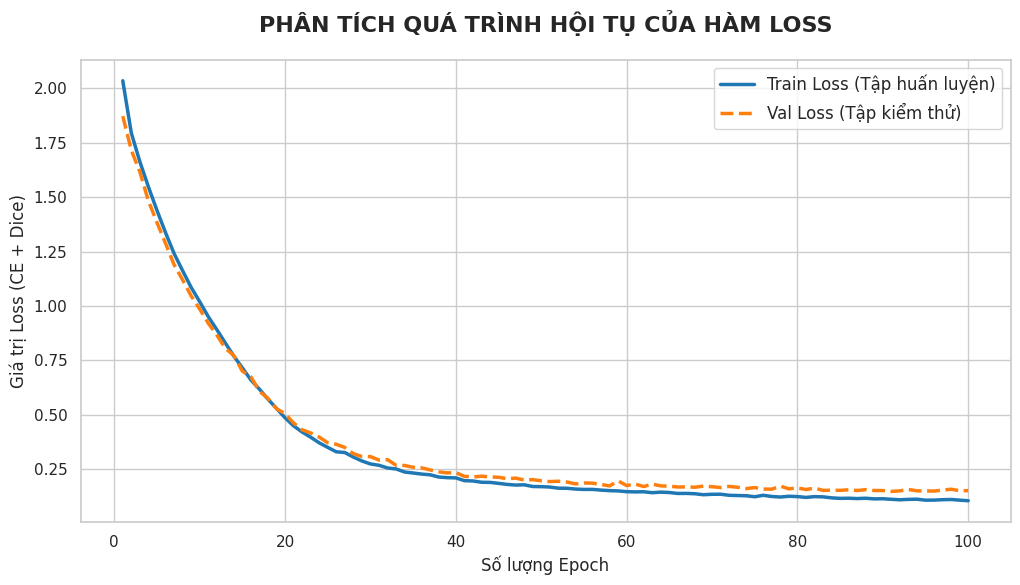

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(df['epoch'], df['tr_loss'], label='Train Loss (Tập huấn luyện)', linewidth=2.5, color='#1f77b4')
plt.plot(df['epoch'], df['va_loss'], label='Val Loss (Tập kiểm thử)', linewidth=2.5, color='#ff7f0e', linestyle='--')

plt.title('PHÂN TÍCH QUÁ TRÌNH HỘI TỤ CỦA HÀM LOSS', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Số lượng Epoch', fontsize=12)
plt.ylabel('Giá trị Loss (CE + Dice)', fontsize=12)
plt.legend(fontsize=12)
plt.show()

**Độ đo Dice**

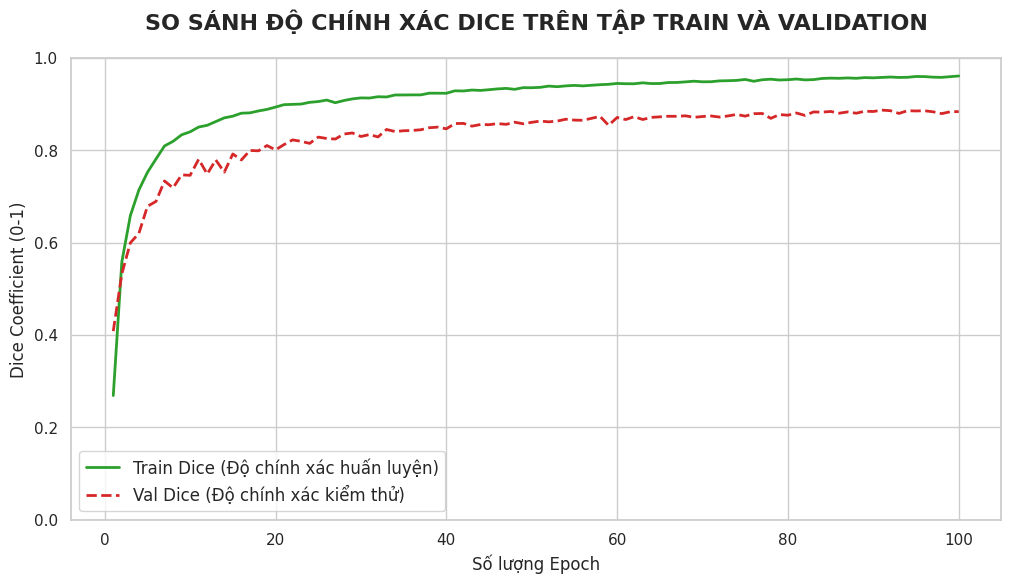

In [10]:
plt.figure(figsize=(12, 6))
plt.plot(df['epoch'], df['tr_dice'], label='Train Dice (Độ chính xác huấn luyện)', color='#2ca02c', linewidth=2)
plt.plot(df['epoch'], df['va_dice'], label='Val Dice (Độ chính xác kiểm thử)', color='#d62728', linewidth=2, linestyle='--')

plt.title('SO SÁNH ĐỘ CHÍNH XÁC DICE TRÊN TẬP TRAIN VÀ VALIDATION', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Số lượng Epoch', fontsize=12)
plt.ylabel('Dice Coefficient (0-1)', fontsize=12)
plt.legend(fontsize=12)
plt.ylim(0, 1)
plt.show()

**Độ đo Dice cho từng vùng (LV-Myo-RV)**

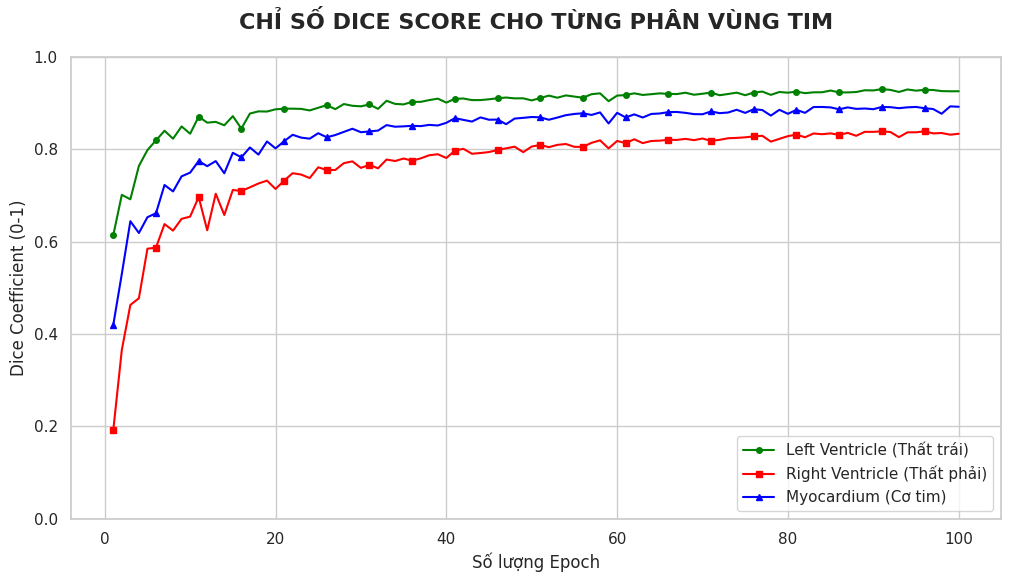

In [11]:
plt.figure(figsize=(12, 6))
plt.plot(df['epoch'], df['lv_d'], label='Left Ventricle (Thất trái)', color='green', marker='o', markersize=4, markevery=5)
plt.plot(df['epoch'], df['rv_d'], label='Right Ventricle (Thất phải)', color='red', marker='s', markersize=4, markevery=5)
plt.plot(df['epoch'], df['myo_d'], label='Myocardium (Cơ tim)', color='blue', marker='^', markersize=4, markevery=5)

plt.title('CHỈ SỐ DICE SCORE CHO TỪNG PHÂN VÙNG TIM', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Số lượng Epoch', fontsize=12)
plt.ylabel('Dice Coefficient (0-1)', fontsize=12)
plt.ylim(0, 1) # Giữ thang đo từ 0 đến 1 để thấy sự tiến bộ rõ rệt
plt.legend(loc='lower right', fontsize=11)
plt.show()

**Biểu đồ Sai số khoảng cách Hausdorff (HD95)**

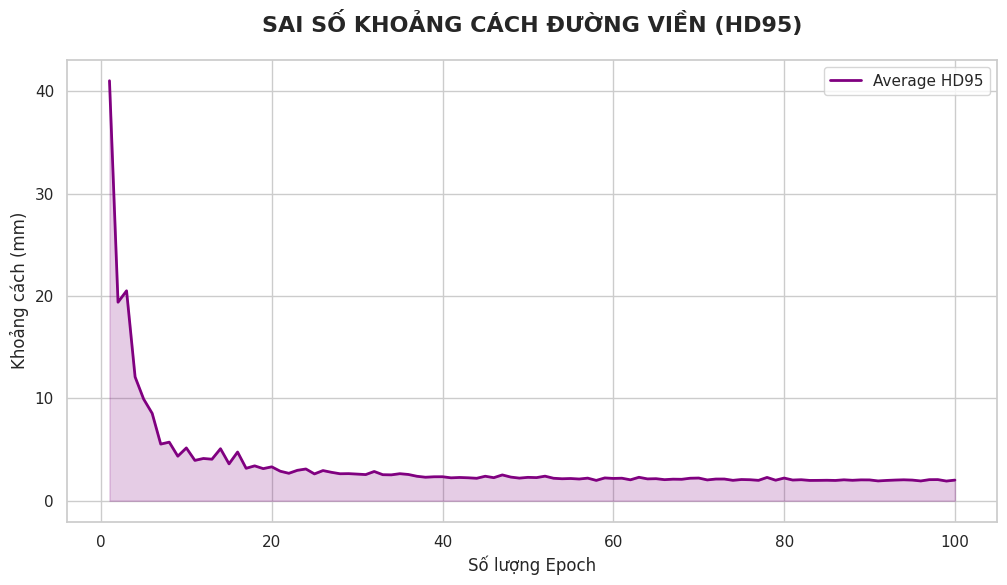

In [12]:
plt.figure(figsize=(12, 6))
plt.fill_between(df['epoch'], df['va_hd95'], color='purple', alpha=0.2)
plt.plot(df['epoch'], df['va_hd95'], color='purple', linewidth=2, label='Average HD95')

plt.title('SAI SỐ KHOẢNG CÁCH ĐƯỜNG VIỀN (HD95)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Số lượng Epoch', fontsize=12)
plt.ylabel('Khoảng cách (mm)', fontsize=12)
plt.legend()
plt.show()

**Biểu đồ chỉ số IoU (Intersection over Union)**

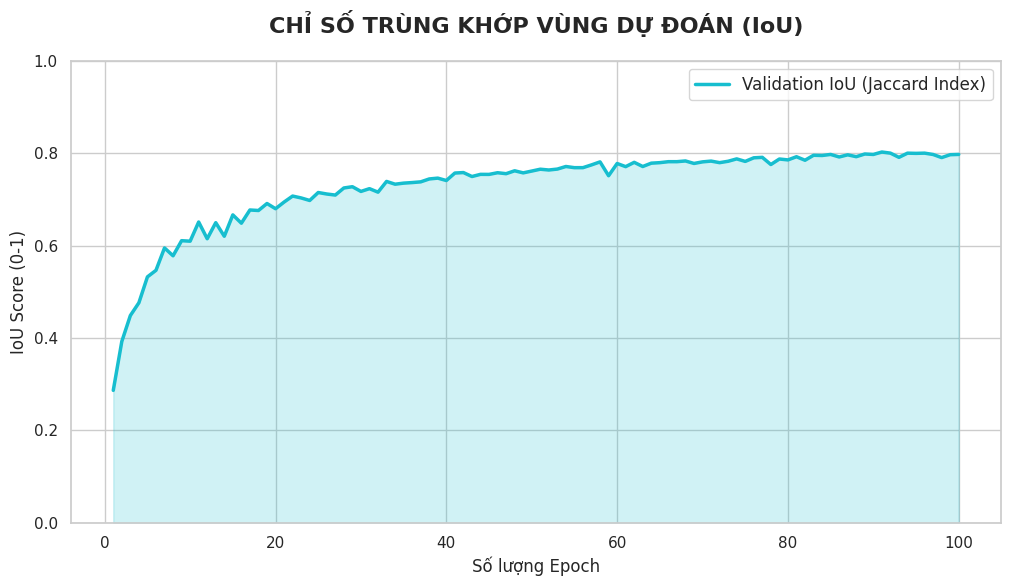

In [13]:
plt.figure(figsize=(12, 6))
plt.fill_between(df['epoch'], df['va_iou'], color='#17becf', alpha=0.2)
plt.plot(df['epoch'], df['va_iou'], color='#17becf', linewidth=2.5, label='Validation IoU (Jaccard Index)')

plt.title('CHỈ SỐ TRÙNG KHỚP VÙNG DỰ ĐOÁN (IoU)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Số lượng Epoch', fontsize=12)
plt.ylabel('IoU Score (0-1)', fontsize=12)
plt.legend(fontsize=12)
plt.ylim(0, 1)
plt.show()

**Time training**

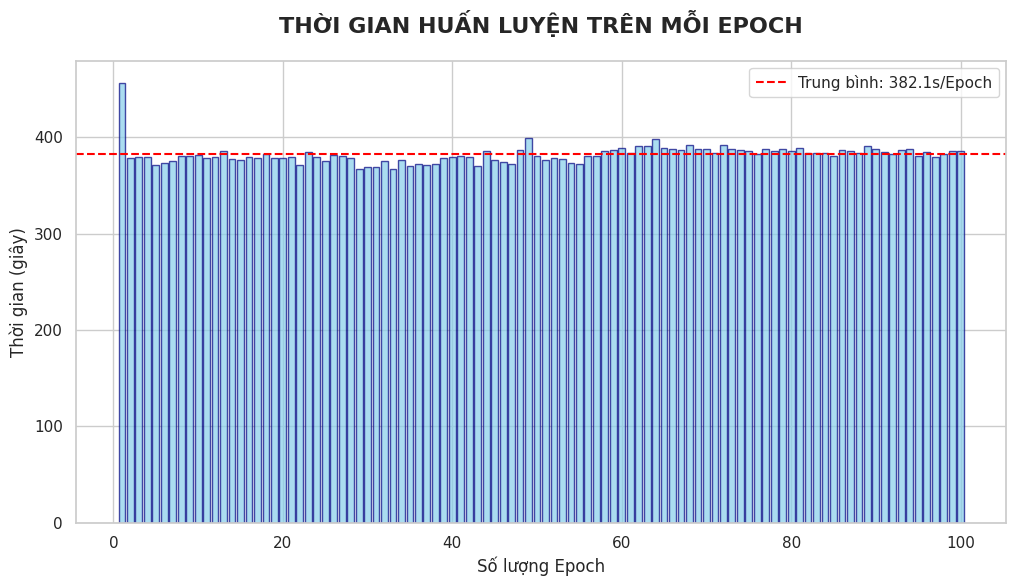

In [14]:
plt.figure(figsize=(12, 6))
plt.bar(df['epoch'], df['time'], color='skyblue', edgecolor='navy', alpha=0.7)
avg_t = df['time'].mean()
plt.axhline(avg_t, color='red', linestyle='--', label=f'Trung bình: {avg_t:.1f}s/Epoch')

plt.title('THỜI GIAN HUẤN LUYỆN TRÊN MỖI EPOCH', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Số lượng Epoch', fontsize=12)
plt.ylabel('Thời gian (giây)', fontsize=12)
plt.legend()
plt.show()

# **Kiểm tra định lượng trên tập Test**

In [17]:
# -------------------------------------------------------------------------
# CELL 9: ĐÁNH GIÁ ĐỊNH LƯỢNG TRÊN TẬP TEST (TEST SET EVALUATION)
# -------------------------------------------------------------------------
model.load_state_dict(torch.load(SAVE_DIR / "best_model.pth"))
model.eval()

test_loader = DataLoader(VolumeDataset(te_items), batch_size=1, shuffle=False)
test_metrics = {'LV':[], 'RV':[], 'MYO':[], 'Overall_Dice':[], 'Overall_IoU':[], 'Overall_HD95':[]}

print(f" đang đánh giá trên {len(te_items)} mẫu tập Test...")

with torch.no_grad():
    for b in tqdm(test_loader):
        img, lab = b["image"].to(DEVICE), b["label"].to(DEVICE)
        out = model(img)
        
        p = torch.argmax(out, 1).cpu().numpy()[0]
        g = lab.cpu().numpy()[0]
        
        m = get_metrics(p, g)
        
        # Lưu metrics từng lớp
        for n in ['LV', 'RV', 'MYO']:
            test_metrics[n].append(m[n])
            
        # Tính trung bình cho mẫu hiện tại
        d_val = np.mean([m[n][0] for n in ['LV', 'RV', 'MYO']])
        i_val = np.mean([m[n][1] for n in ['LV', 'RV', 'MYO']])
        h_val = np.mean([m[n][2] for n in ['LV', 'RV', 'MYO']])
        
        test_metrics['Overall_Dice'].append(d_val)
        test_metrics['Overall_IoU'].append(i_val)
        test_metrics['Overall_HD95'].append(h_val)

# Tính trung bình cộng tập Test
print("\n" + "="*50)
print("KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST")
print("="*50)
print(f"Dice Score trung bình: {np.mean(test_metrics['Overall_Dice']):.4f}")
print(f"IoU trung bình:        {np.mean(test_metrics['Overall_IoU']):.4f}")
print(f"HD95 trung bình:       {np.mean(test_metrics['Overall_HD95']):.2f} mm")
print("-" * 30)
for n in ['LV', 'RV', 'MYO']:
    class_stats = np.mean(test_metrics[n], 0)
    print(f"Vùng {n:3}: Dice: {class_stats[0]:.4f} | IoU: {class_stats[1]:.4f} | HD95: {class_stats[2]:.2f}")
print("="*50)

 đang đánh giá trên 108 mẫu tập Test...


100%|██████████| 108/108 [02:08<00:00,  1.19s/it]


KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST
Dice Score trung bình: 0.8885
IoU trung bình:        0.8049
HD95 trung bình:       1.93 mm
------------------------------
Vùng LV : Dice: 0.9296 | IoU: 0.8712 | HD95: 1.81
Vùng RV : Dice: 0.8396 | IoU: 0.7266 | HD95: 1.29
Vùng MYO: Dice: 0.8962 | IoU: 0.8170 | HD95: 2.70


**Trực quan hóa kết quả**

Hiển thị mẫu Test ID: 70


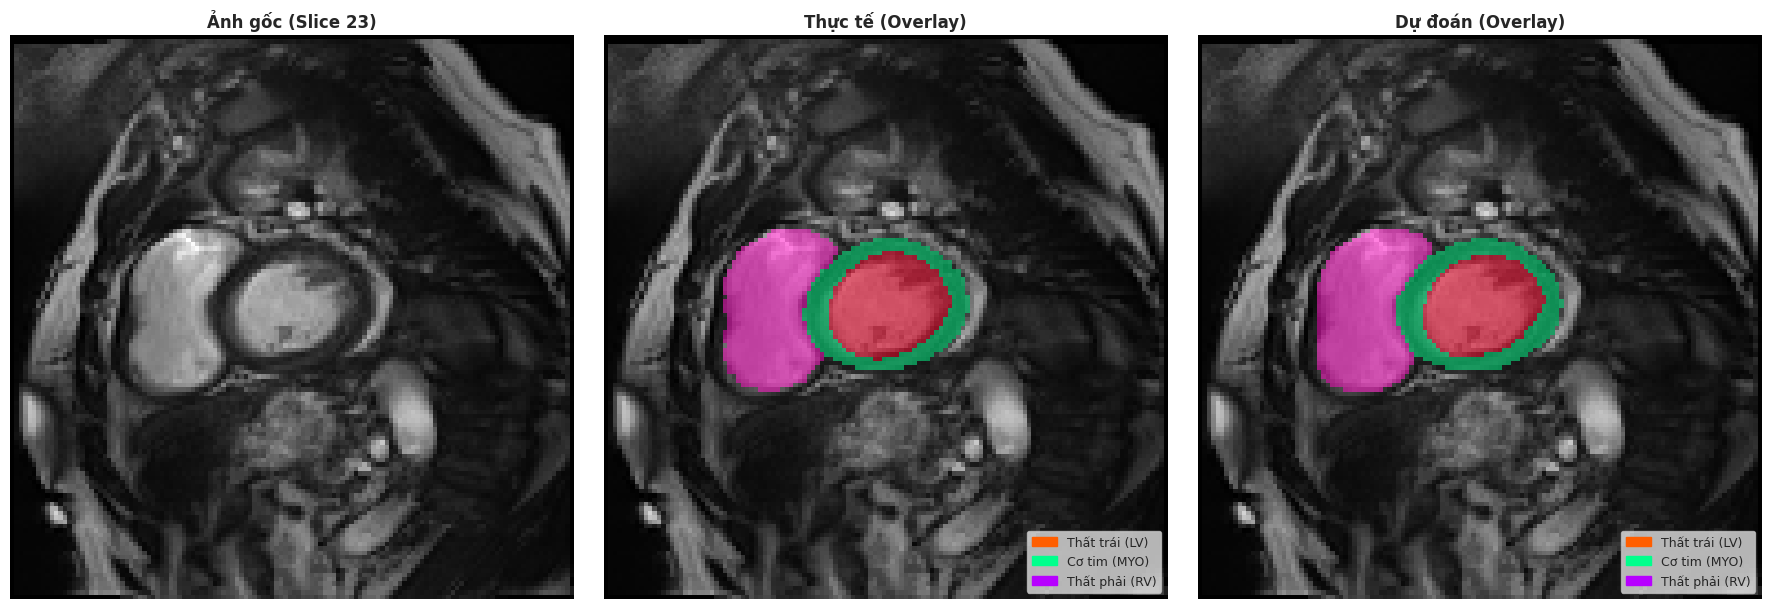

Hiển thị mẫu Test ID: 26


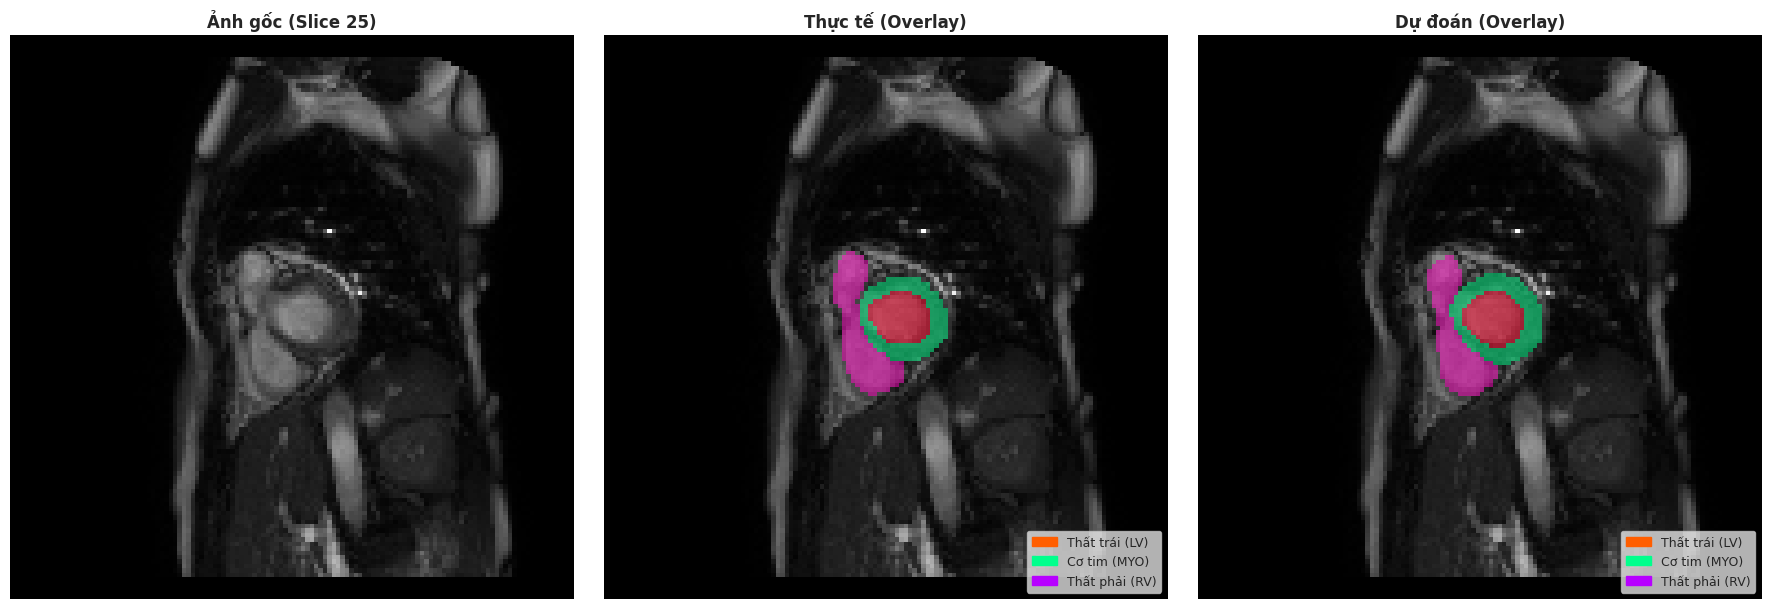

Hiển thị mẫu Test ID: 81


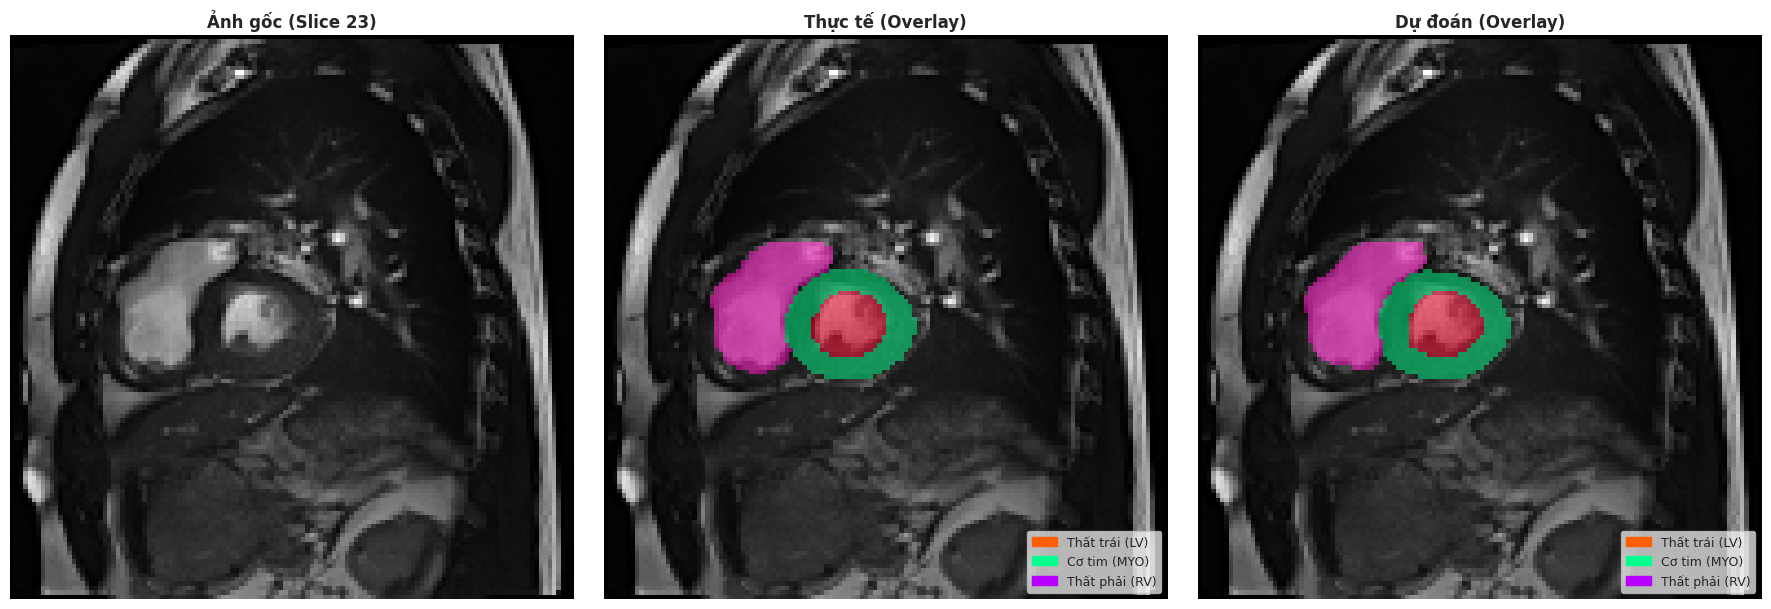

Hiển thị mẫu Test ID: 27


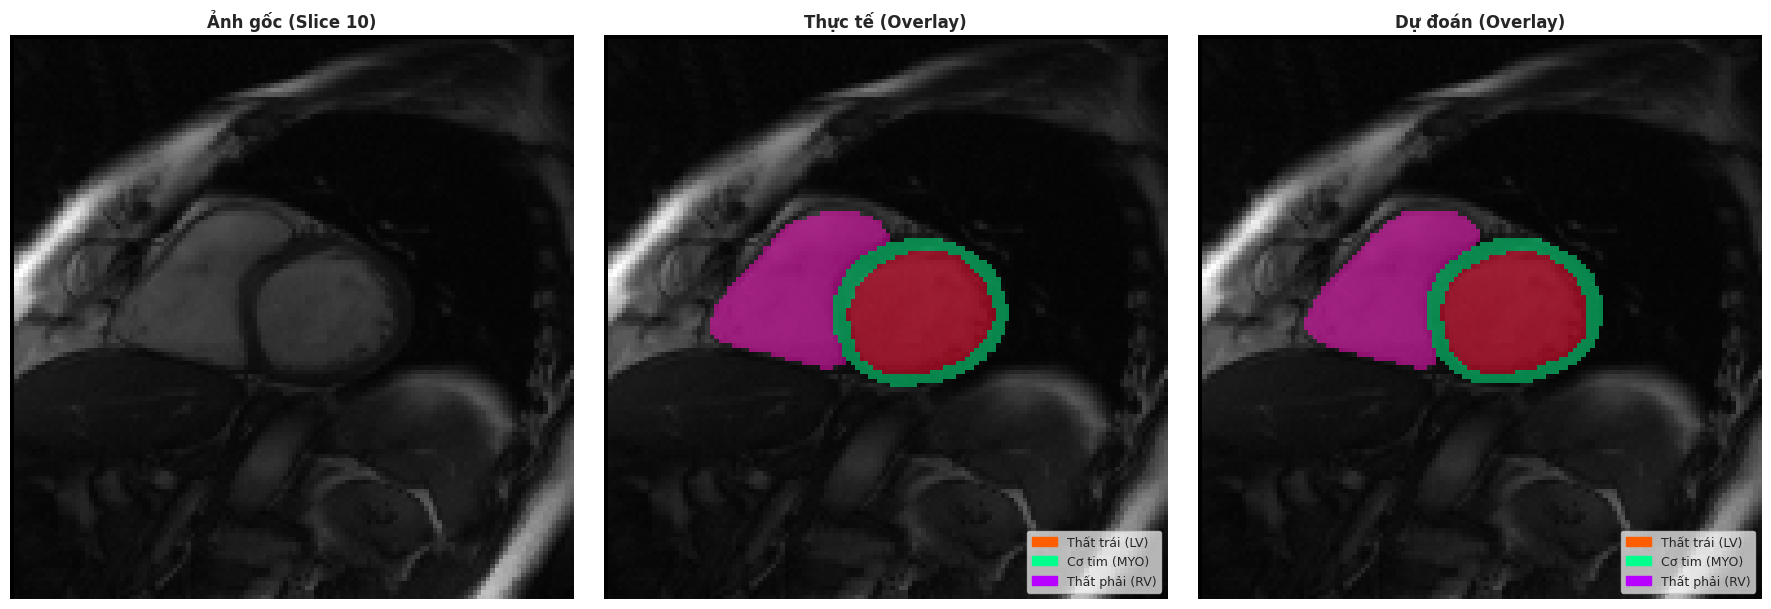

Hiển thị mẫu Test ID: 73


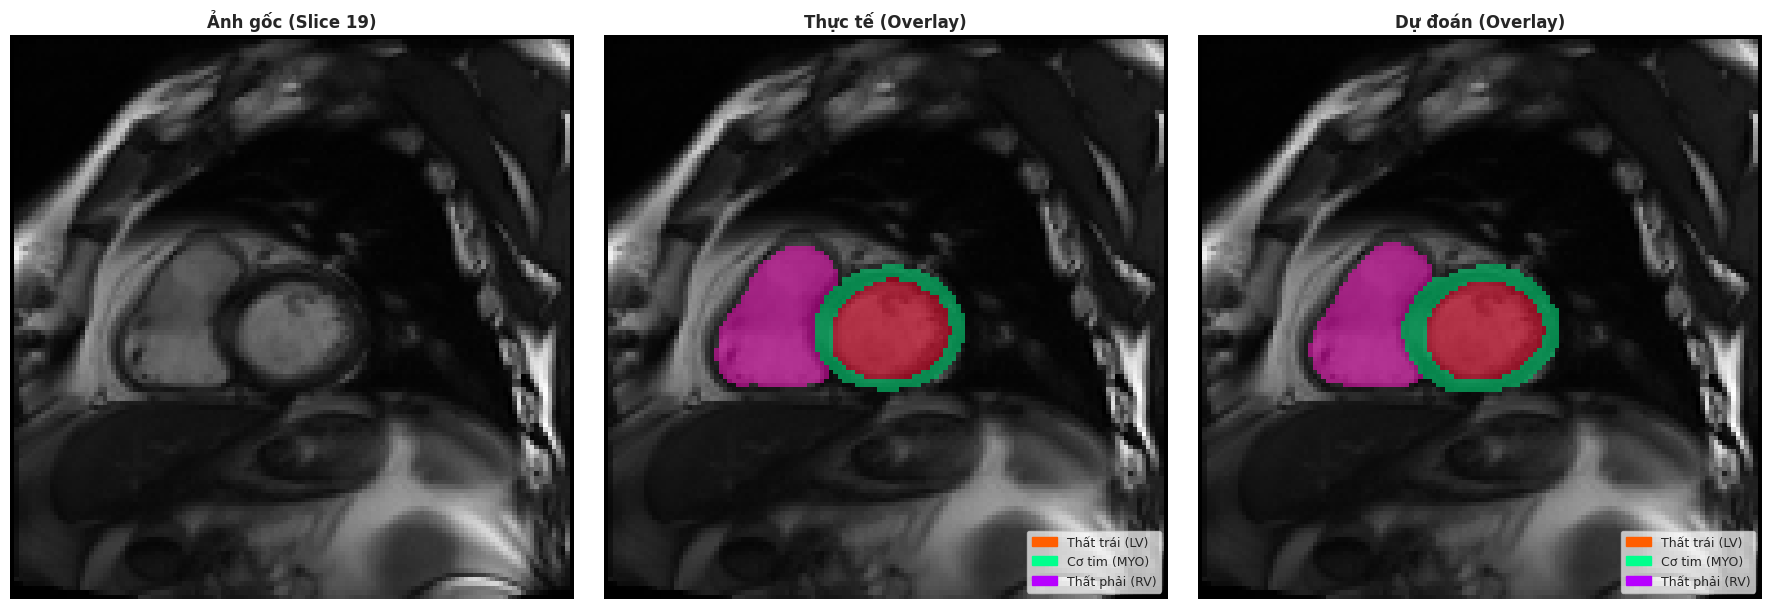

Hiển thị mẫu Test ID: 55


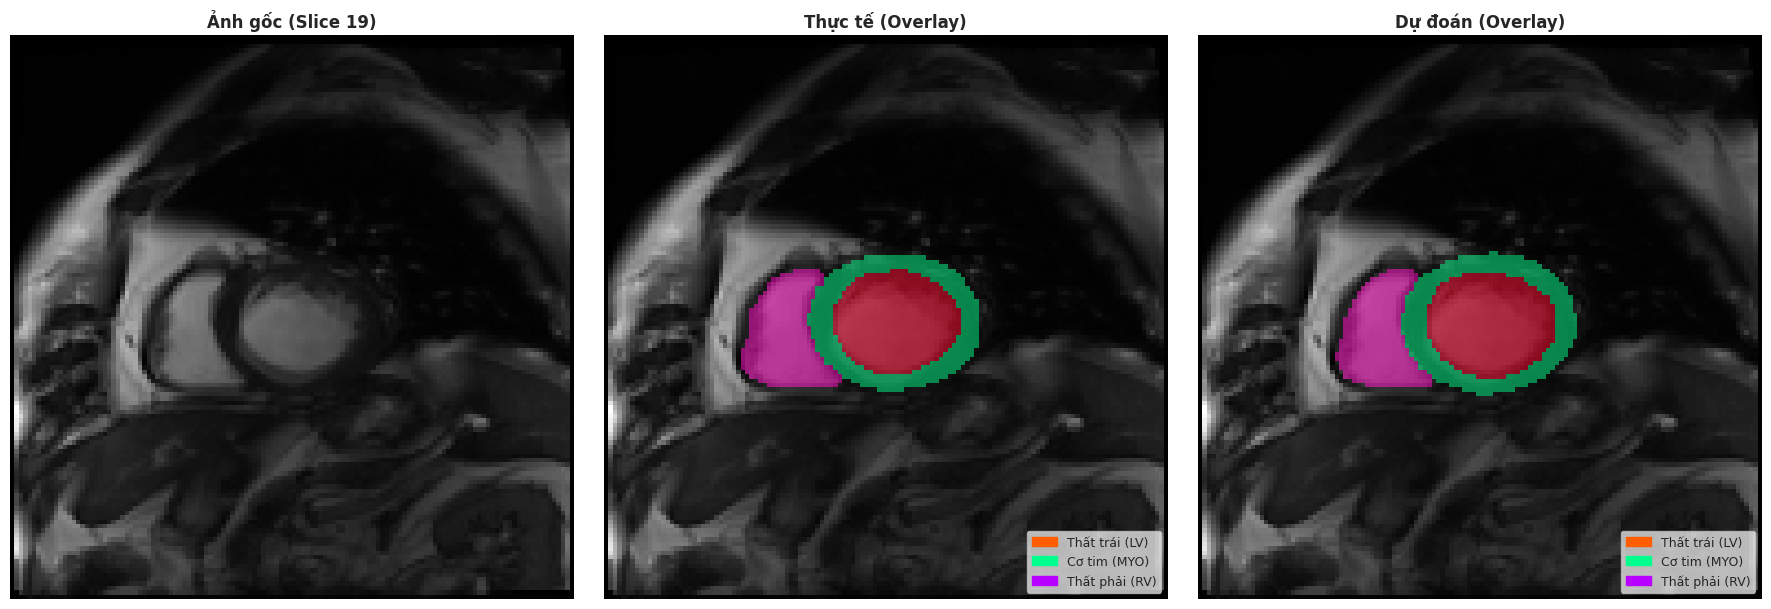

In [47]:
# -------------------------------------------------------------------------
# CELL 10: TRỰC QUAN HÓA KẾT QUẢ DỰ ĐOÁN (MÀU GIST_RAINBOW + CHÚ THÍCH)
# -------------------------------------------------------------------------
import numpy as np
import matplotlib.patches as mpatches

def visualize_test_sample_overlay(sample_idx=0):
    model.eval()
    dataset = VolumeDataset(te_items)
    data = dataset[sample_idx]
    
    img = data['image'].unsqueeze(0).to(DEVICE)
    label = data['label'].numpy() 
    
    with torch.no_grad():
        out = model(img)
        pred = torch.argmax(out, 1).cpu().numpy()[0] 
    
    img_np = img.cpu().numpy()[0, 0] 
    
    # Tìm lát cắt chứa nhiều tim nhất
    slice_idx = np.argmax(np.sum(label > 0, axis=(0, 1)))
    
    # --- TRÍCH XUẤT MÀU TỪ GIST_RAINBOW ĐỂ LÀM CHÚ THÍCH ---
    # Vì gist_rainbow chia dải màu theo giá trị 1, 2, 3 nên ta lấy màu tương ứng
    cmap_ref = plt.get_cmap('gist_rainbow')
    # MnM-2 thường: 1=LV, 2=MYO, 3=RV. Ta lấy màu tại các vị trí tương ứng trong dải [0, 1]
    color_lv  = cmap_ref(0.1) # Thường là Đỏ/Cam
    color_myo = cmap_ref(0.5) # Thường là Xanh lá/Vàng
    color_rv  = cmap_ref(0.9) # Thường là Xanh dương/Tím

    lv_patch  = mpatches.Patch(color=color_lv,  label='Thất trái (LV)')
    myo_patch = mpatches.Patch(color=color_myo, label='Cơ tim (MYO)')
    rv_patch  = mpatches.Patch(color=color_rv,  label='Thất phải (RV)')

    plt.figure(figsize=(18, 6))
    
    # 1. Ô thứ nhất: Ảnh MRI gốc
    plt.subplot(1, 3, 1)
    plt.imshow(img_np[:, :, slice_idx], cmap='gray')
    plt.title(f"Ảnh gốc (Slice {slice_idx})", fontsize=12, fontweight='bold')
    plt.axis('off')
    
    # 2. Ô thứ hai: Thực tế (Ground Truth) chồng lên ảnh gốc
    ax2 = plt.subplot(1, 3, 2)
    plt.imshow(img_np[:, :, slice_idx], cmap='gray')
    gt_overlay = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
    plt.imshow(gt_overlay, cmap='gist_rainbow', alpha=0.5) 
    plt.title("Thực tế (Overlay)", fontsize=12, fontweight='bold')
    plt.axis('off')
    ax2.legend(handles=[lv_patch, myo_patch, rv_patch], loc='lower right', fontsize=9, framealpha=0.7)
    
    # 3. Ô thứ ba: Dự đoán (Prediction) chồng lên ảnh gốc
    ax3 = plt.subplot(1, 3, 3)
    plt.imshow(img_np[:, :, slice_idx], cmap='gray')
    pred_overlay = np.ma.masked_where(pred[:, :, slice_idx] == 0, pred[:, :, slice_idx])
    plt.imshow(pred_overlay, cmap='gist_rainbow', alpha=0.5)
    plt.title("Dự đoán (Overlay)", fontsize=12, fontweight='bold')
    plt.axis('off')
    ax3.legend(handles=[lv_patch, myo_patch, rv_patch], loc='lower right', fontsize=9, framealpha=0.7)
    
    plt.tight_layout()
    plt.show()

# Hiển thị thử 6 mẫu
import random
for i in range(6):
    idx = random.randint(0, len(te_items)-1)
    print(f"Hiển thị mẫu Test ID: {idx}")
    visualize_test_sample_overlay(idx)

Hiển thị mẫu Test ID: 99


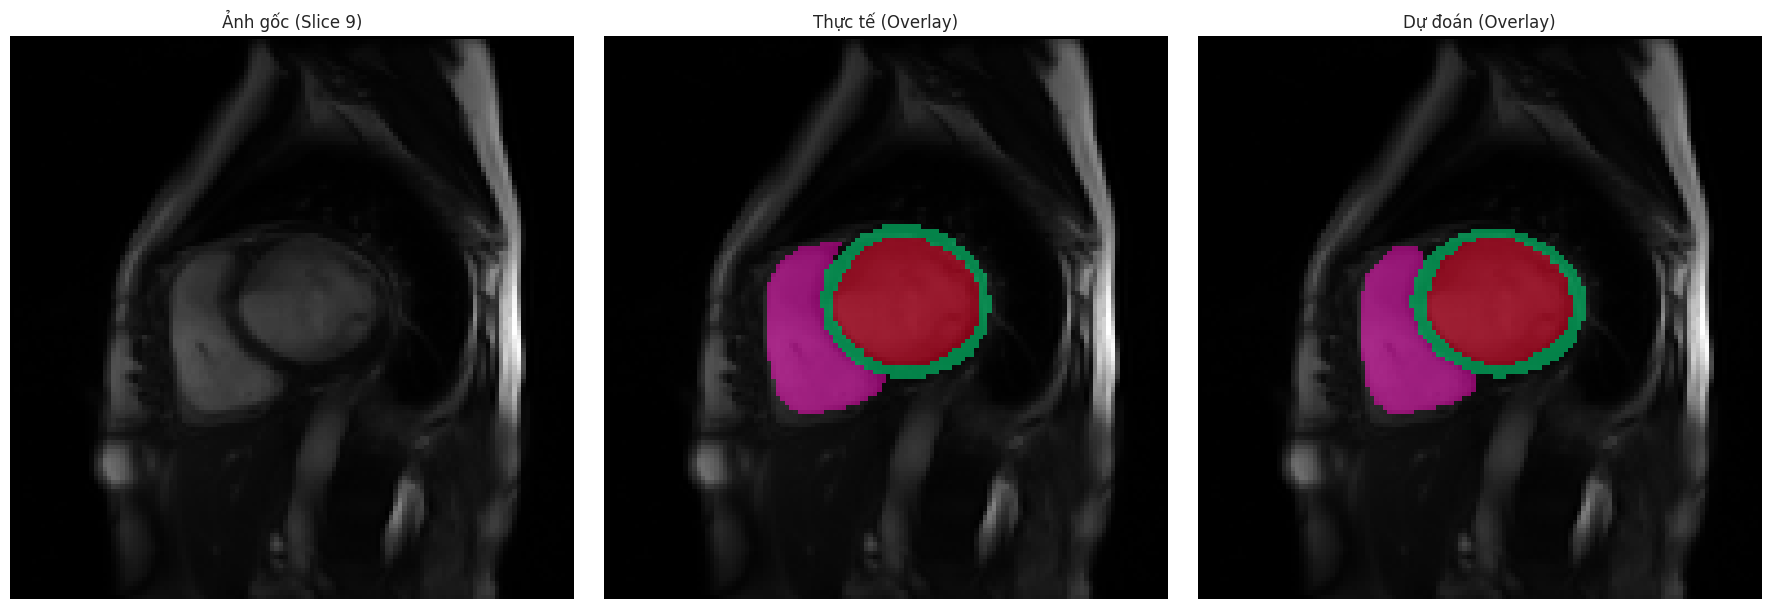

Hiển thị mẫu Test ID: 107


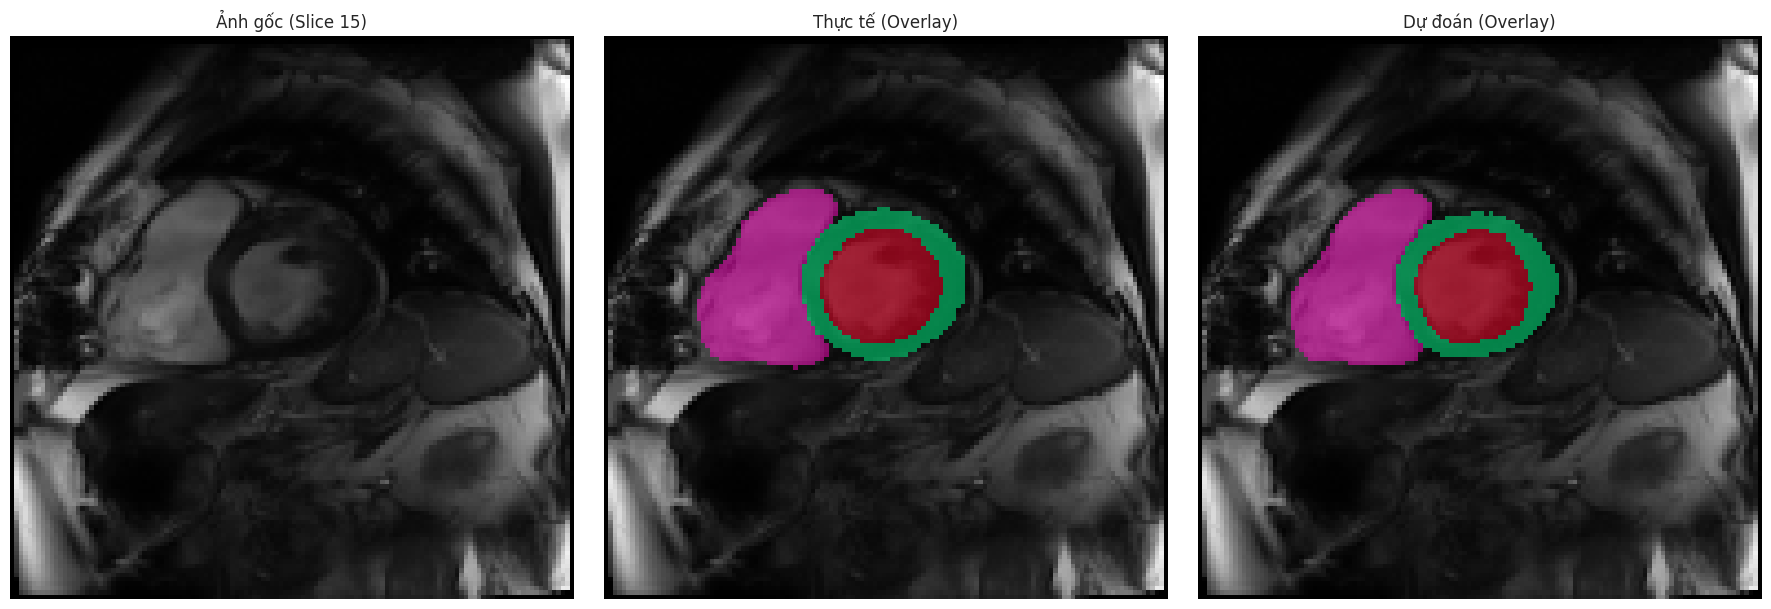

Hiển thị mẫu Test ID: 71


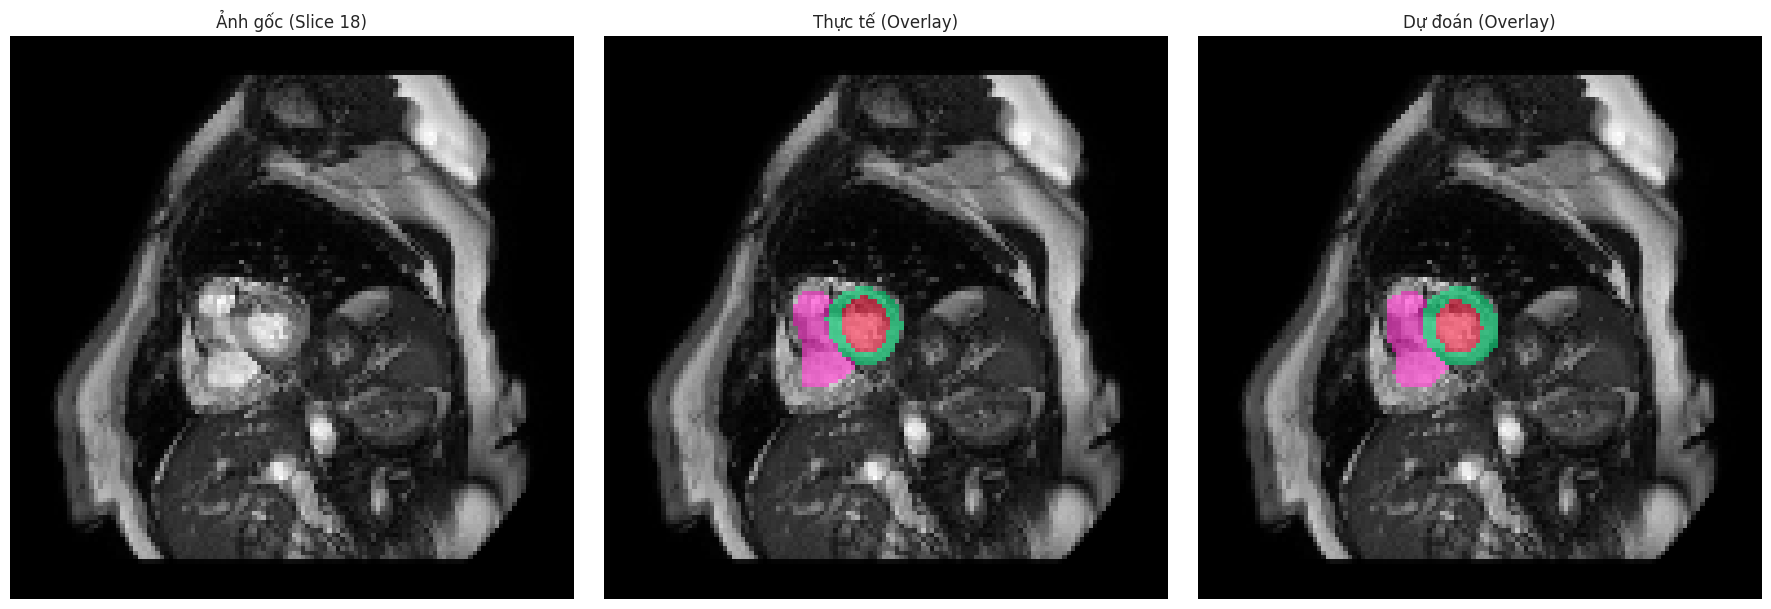

Hiển thị mẫu Test ID: 104


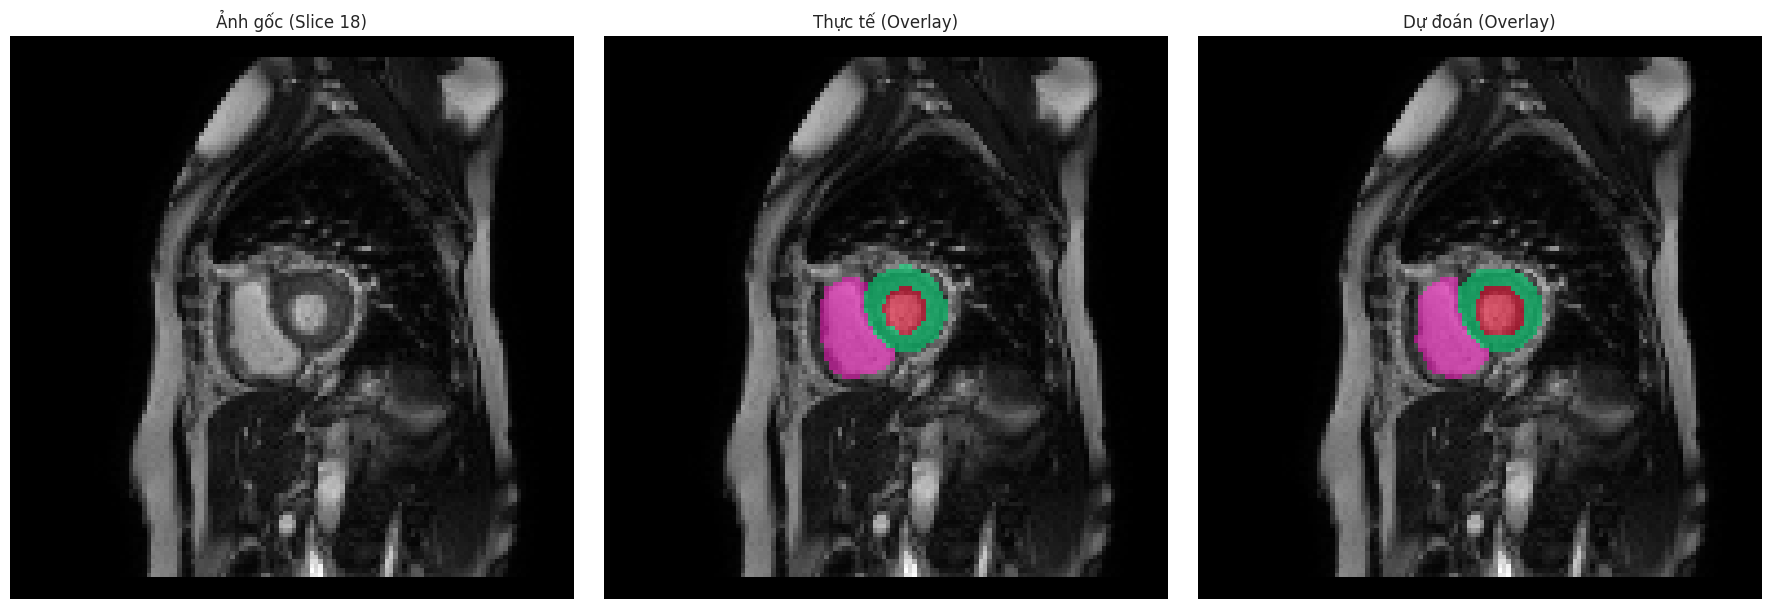

Hiển thị mẫu Test ID: 0


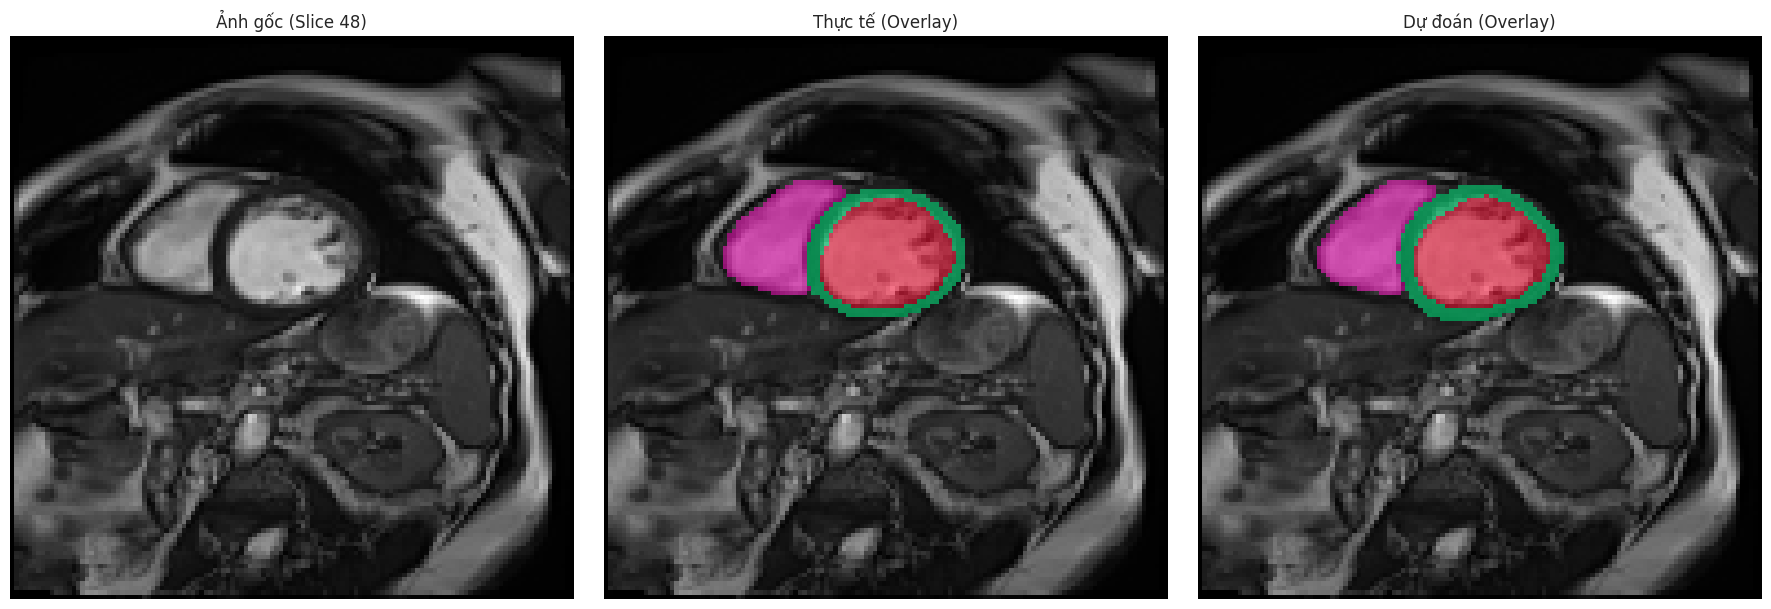

Hiển thị mẫu Test ID: 36


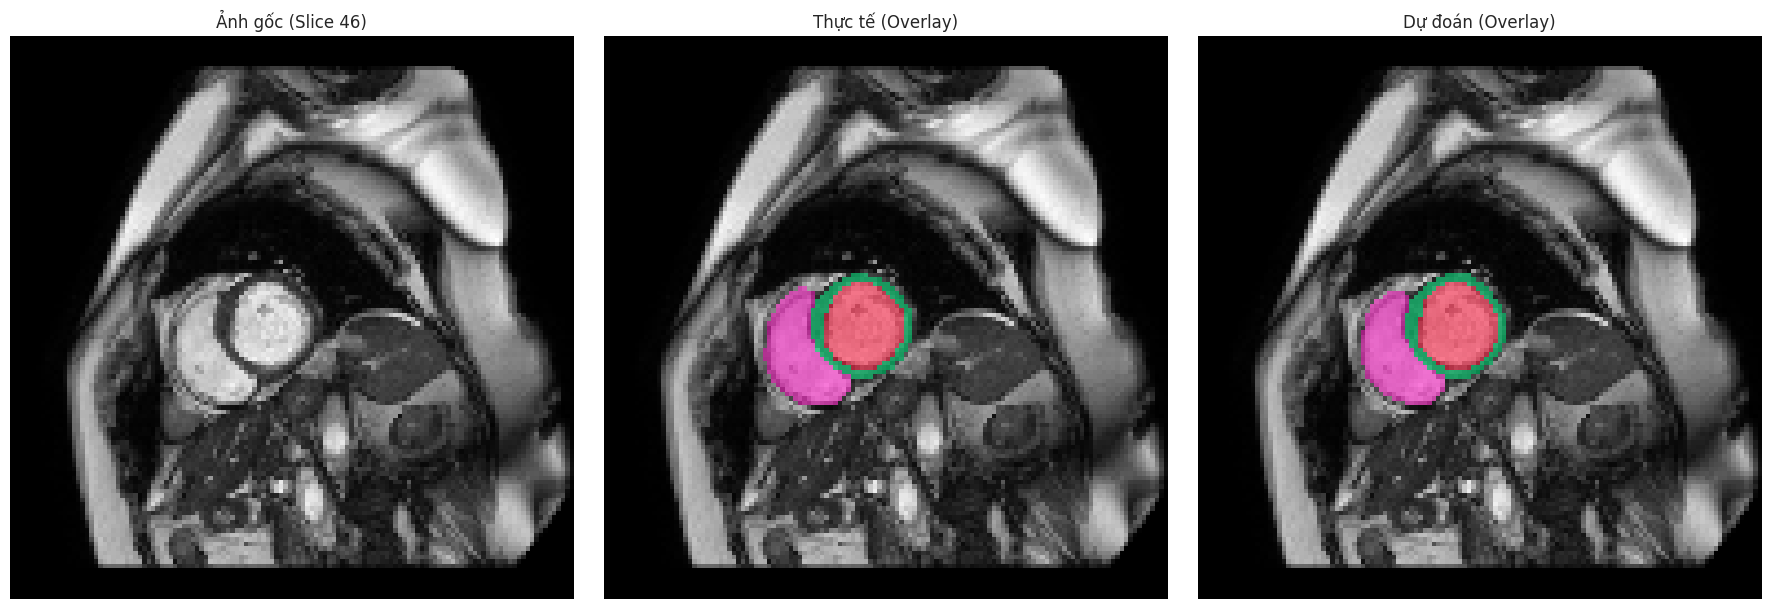

In [30]:
# -------------------------------------------------------------------------
# CELL 10: TRỰC QUAN HÓA KẾT QUẢ DỰ ĐOÁN (STYLE OVERLAY)
# -------------------------------------------------------------------------
import numpy as np

def visualize_test_sample_overlay(sample_idx=0):
    model.eval()
    # Sử dụng danh sách te_items mà bạn đã chạy thành công
    dataset = VolumeDataset(te_items)
    data = dataset[sample_idx]
    
    img = data['image'].unsqueeze(0).to(DEVICE)
    label = data['label'].numpy() # (H, W, D)
    
    with torch.no_grad():
        out = model(img)
        pred = torch.argmax(out, 1).cpu().numpy()[0] # (H, W, D)
    
    img_np = img.cpu().numpy()[0, 0] # Lấy ảnh gốc (H, W, D)
    
    # Tìm lát cắt có chứa nhiều tim nhất để hiển thị cho đẹp
    # Thay vì lấy lát cắt ở giữa cố định, ta tìm lát cắt có nhãn (label > 0) nhiều nhất
    slice_idx = np.argmax(np.sum(label > 0, axis=(0, 1)))
    
    plt.figure(figsize=(18, 6))
    
    # 1. Ô thứ nhất: Ảnh MRI gốc
    plt.subplot(1, 3, 1)
    plt.imshow(img_np[:, :, slice_idx], cmap='gray')
    plt.title(f"Ảnh gốc (Slice {slice_idx})")
    plt.axis('off')
    
    # 2. Ô thứ hai: Thực tế (Ground Truth) chồng lên ảnh gốc
    plt.subplot(1, 3, 2)
    plt.imshow(img_np[:, :, slice_idx], cmap='gray') # Vẽ lớp nền MRI
    # Tạo mặt nạ trong suốt cho vùng nền (vùng = 0)
    gt_overlay = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
    plt.imshow(gt_overlay, cmap='gist_rainbow', alpha=0.5) # Vẽ lớp màu đè lên
    plt.title("Thực tế (Overlay)")
    plt.axis('off')
    
    # 3. Ô thứ ba: Dự đoán (Prediction) chồng lên ảnh gốc
    plt.subplot(1, 3, 3)
    plt.imshow(img_np[:, :, slice_idx], cmap='gray') # Vẽ lớp nền MRI
    # Tạo mặt nạ trong suốt cho vùng nền dự đoán
    pred_overlay = np.ma.masked_where(pred[:, :, slice_idx] == 0, pred[:, :, slice_idx])
    plt.imshow(pred_overlay, cmap='gist_rainbow', alpha=0.5) # Vẽ lớp màu đè lên
    plt.title("Dự đoán (Overlay)")
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

# Hiển thị thử 6 mẫu ngẫu nhiên từ danh sách te_items của bạn
import random
for i in range(6):
    idx = random.randint(0, len(te_items)-1)
    print(f"Hiển thị mẫu Test ID: {idx}")
    visualize_test_sample_overlay(idx)

# **XAI**

In [73]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

# ---------------------------------------------------------
# LỚP HỖ TRỢ TRÍCH XUẤT GRAD-CAM 3D
# ---------------------------------------------------------
class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, class_idx):
        self.model.zero_grad()
        output = self.model(input_tensor)
        # Tính toán dựa trên class_idx (1:LV, 2:MYO, 3:RV)
        loss = output[0, class_idx].sum()
        loss.backward(retain_graph=True)

        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        cam = F.relu(cam).detach().cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

# Tự động xác định target layer cho Grad-CAM (lớp Conv3D cuối cùng)
conv_layers = [m for m in model.modules() if isinstance(m, torch.nn.Conv3d)]
target_layer_gradcam = conv_layers[-1] 
# Lớp Encoder đầu tiên để giải thích đặc trưng sơ cấp
encoder_layer = conv_layers[0] 

cam_extractor = GradCAM3D(model, target_layer_gradcam)

📌 Đang phân tích mẫu bệnh nhân ID: 50


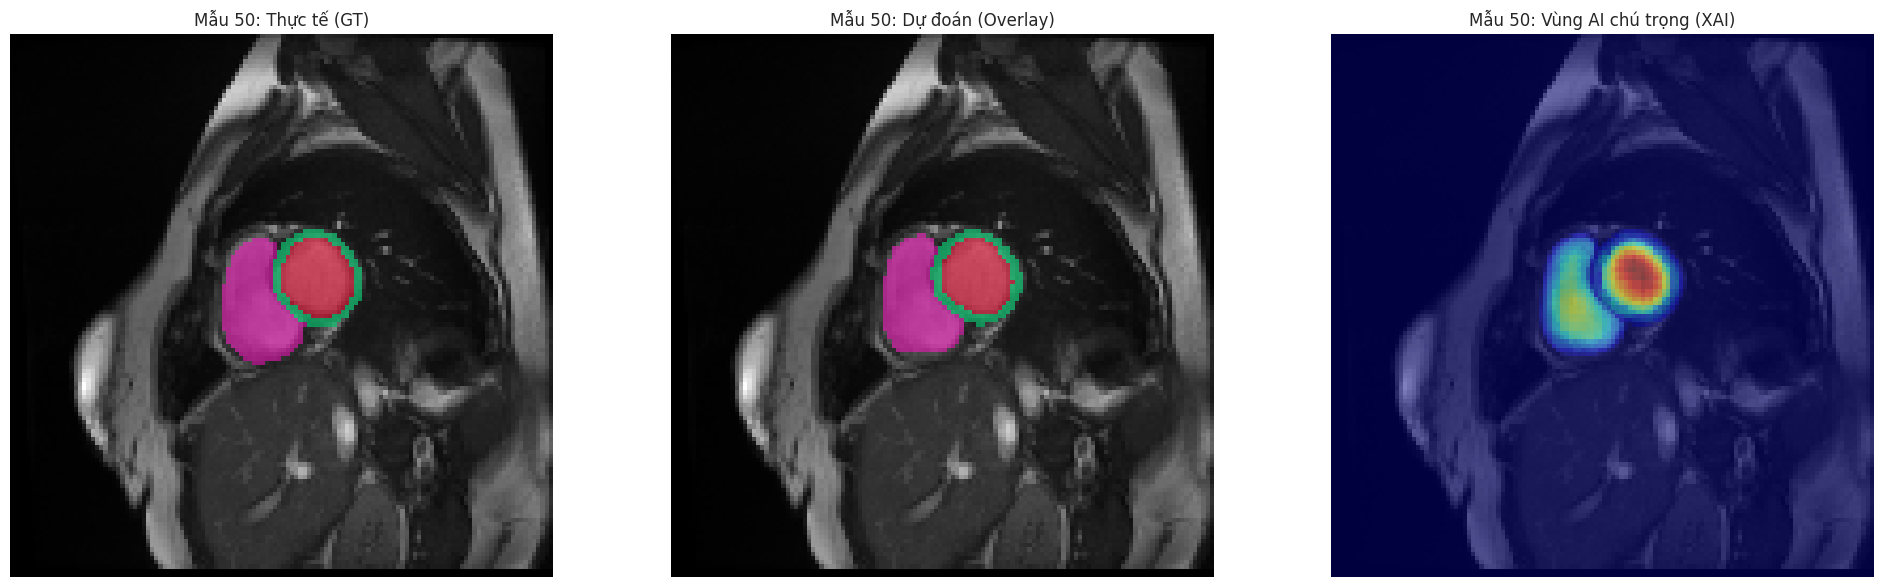

📌 Đang phân tích mẫu bệnh nhân ID: 22


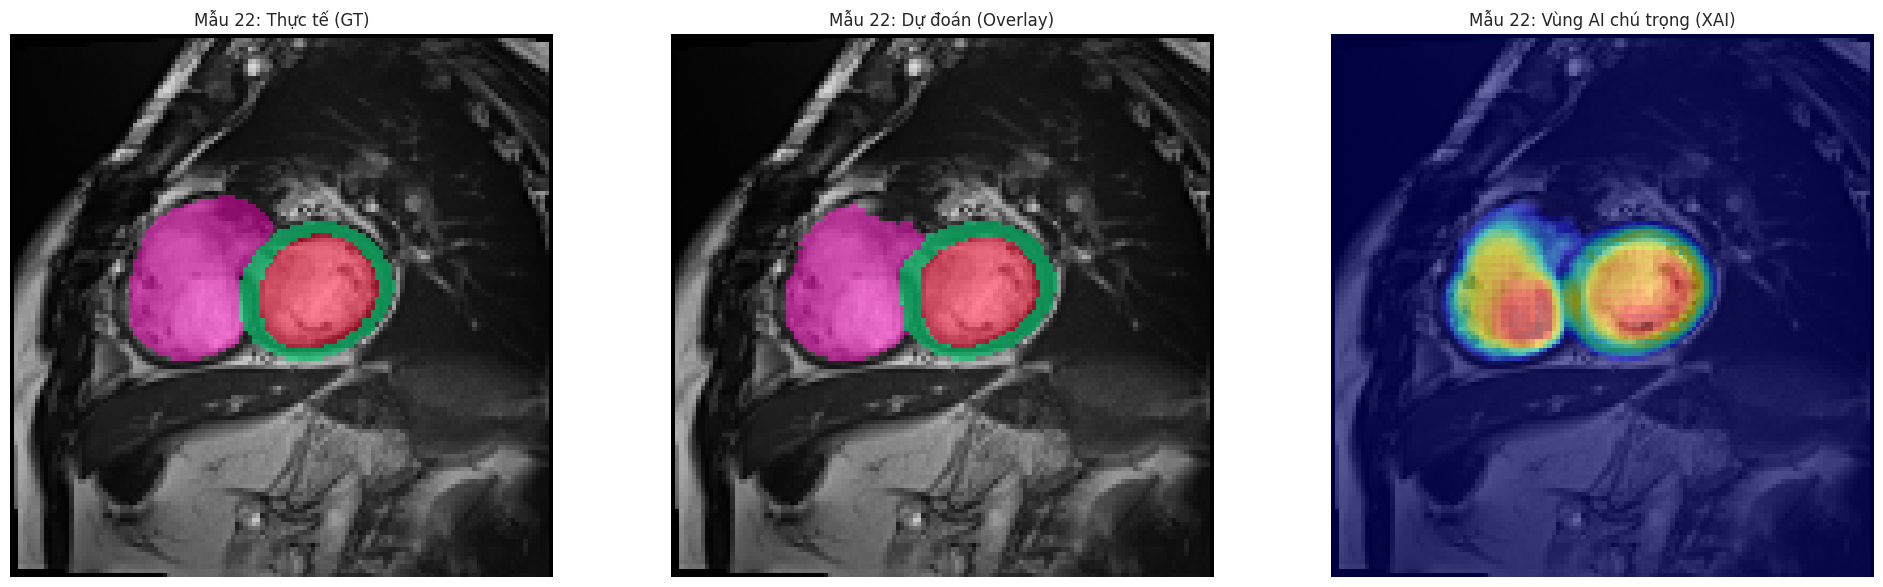

📌 Đang phân tích mẫu bệnh nhân ID: 107


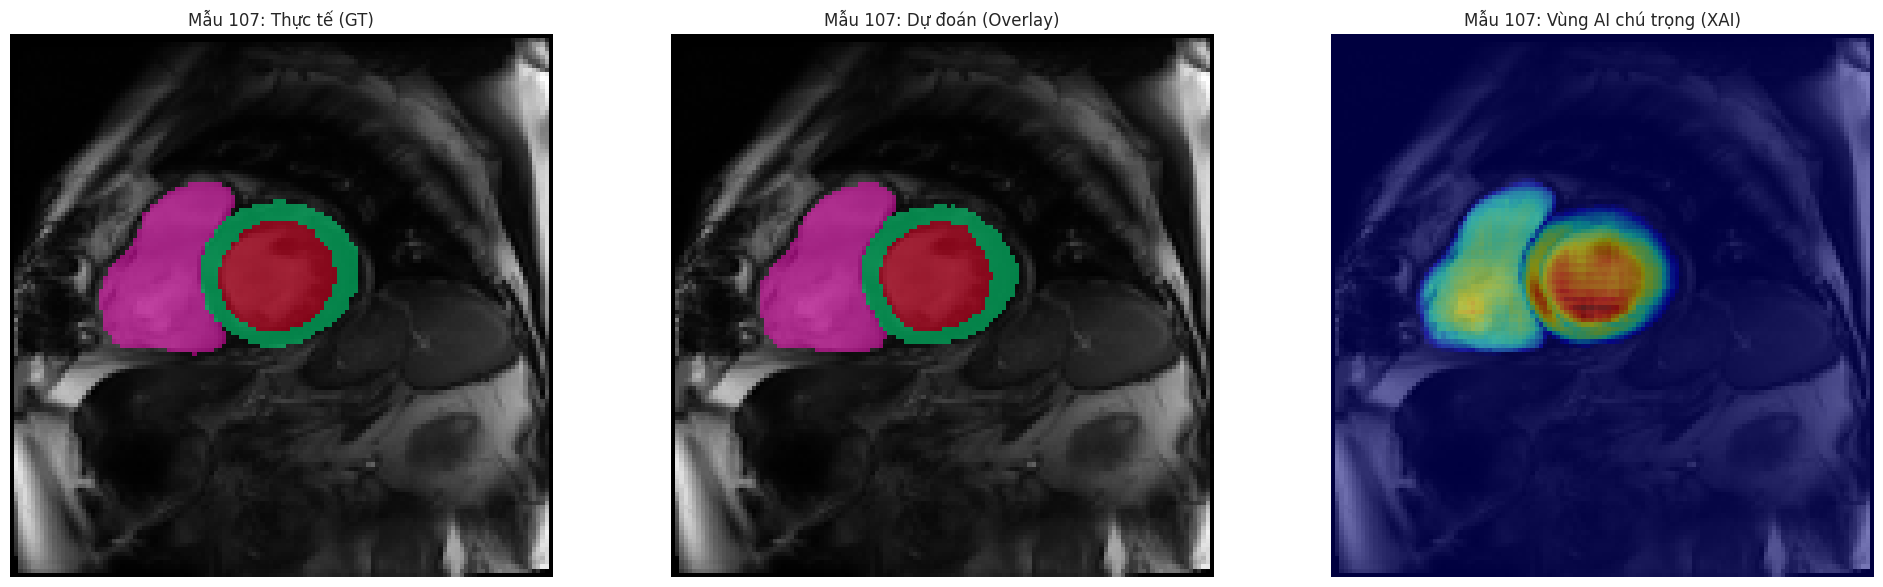

📌 Đang phân tích mẫu bệnh nhân ID: 38


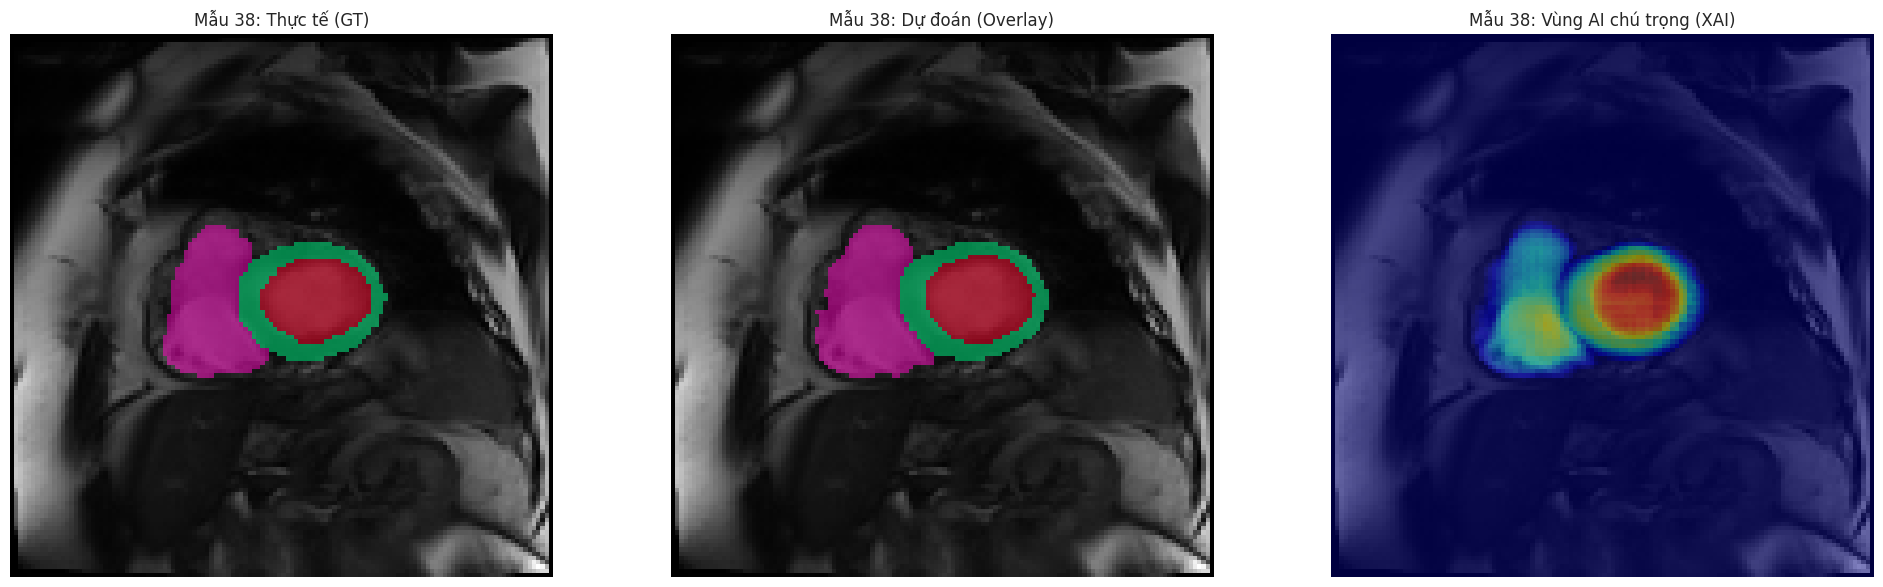

📌 Đang phân tích mẫu bệnh nhân ID: 18


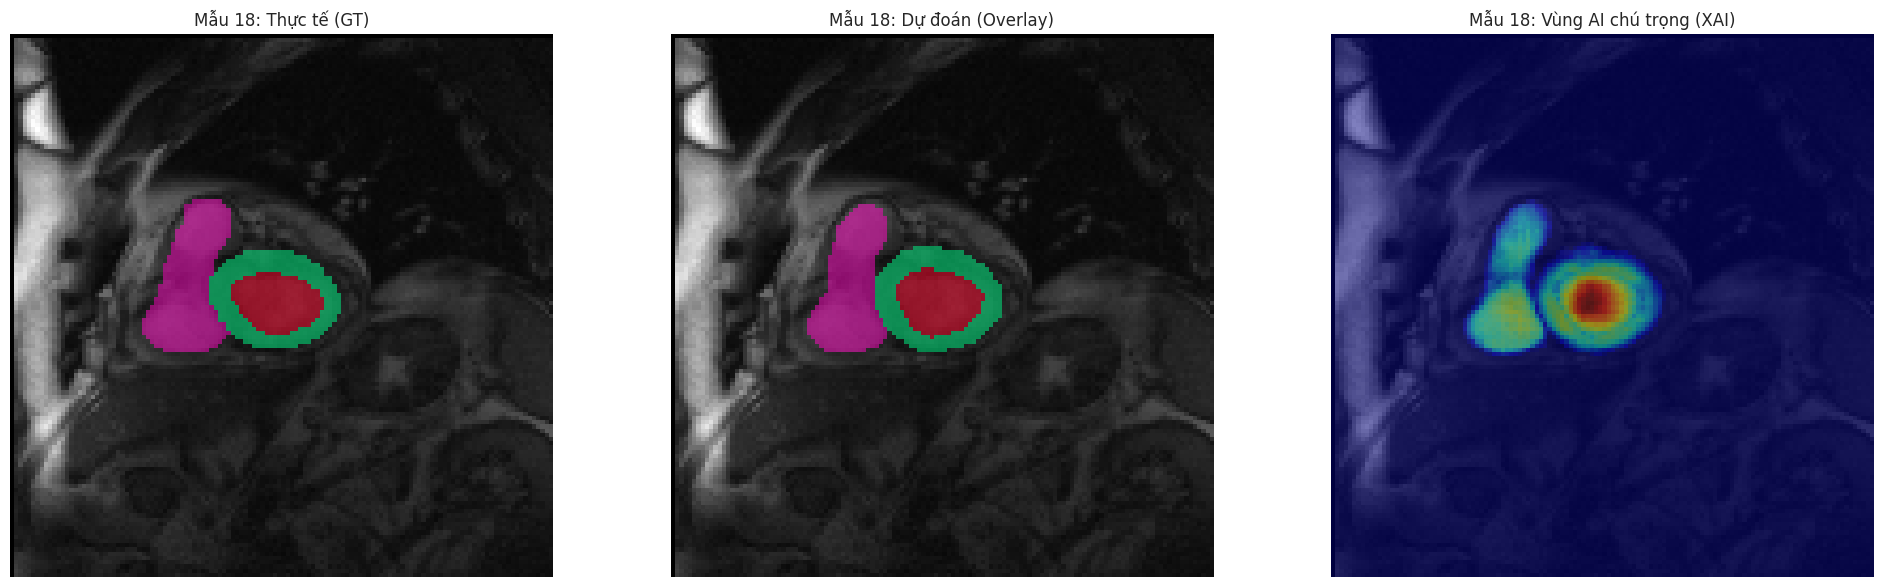

📌 Đang phân tích mẫu bệnh nhân ID: 35


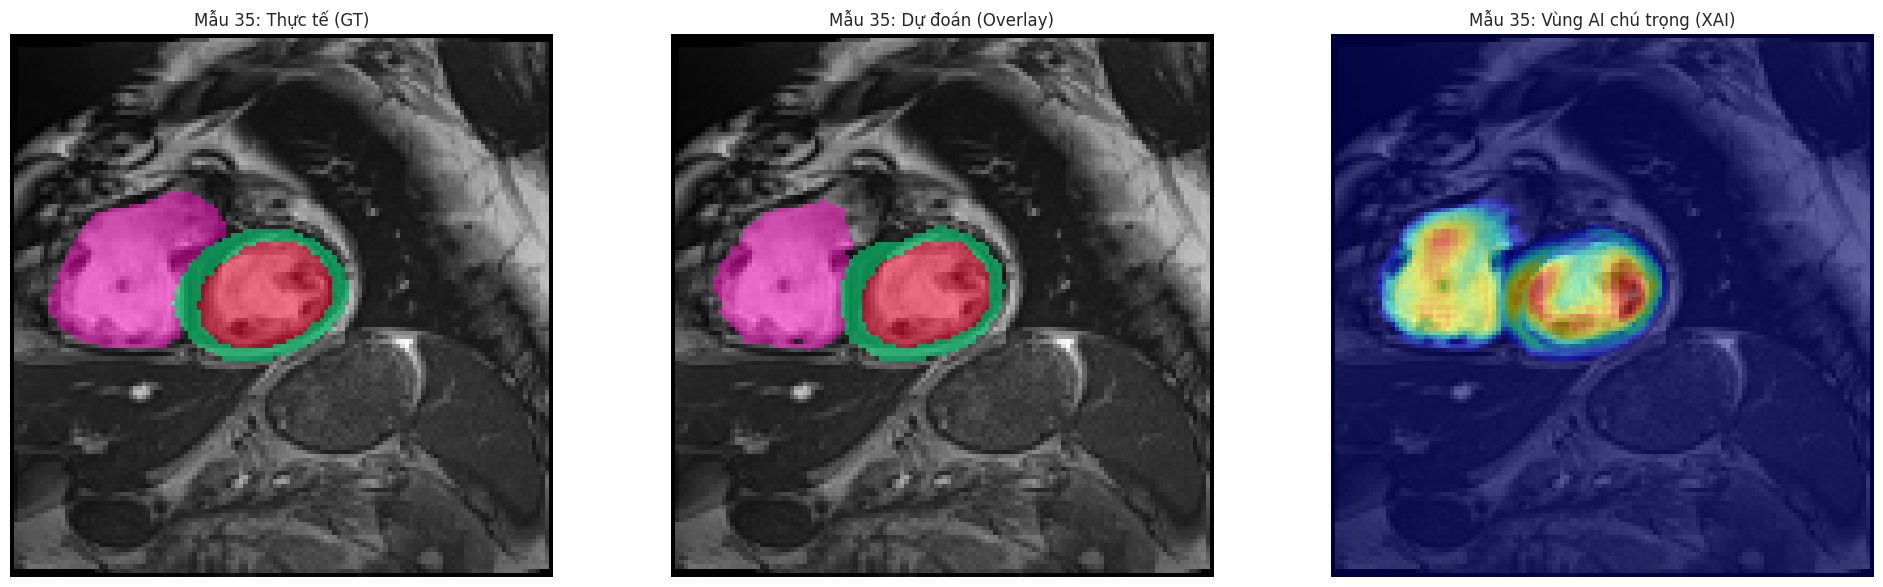

In [79]:
# -------------------------------------------------------------------------
# CELL: DASHBOARD TỔNG HỢP - DỰ ĐOÁN & GIẢI THÍCH GRAD-CAM (MULTI-SAMPLE)
# -------------------------------------------------------------------------
import random
import torch.nn.functional as F
from scipy.ndimage import zoom

def visualize_xai_prediction_dashboard(num_samples=6):
    model.eval()
    dataset = VolumeDataset(te_items)
    
    # Tự động xác định lớp Conv3D cuối cùng để làm mục tiêu giải thích
    target_layer = [m for m in model.modules() if isinstance(m, torch.nn.Conv3d)][-1]
    cam_extractor = GradCAM3D(model, target_layer)

    # Chọn ngẫu nhiên các mẫu từ tập Test
    sample_indices = random.sample(range(len(te_items)), num_samples)

    for idx in sample_indices:
        print(f"📌 Đang phân tích mẫu bệnh nhân ID: {idx}")
        data = dataset[idx]
        img = data['image'].unsqueeze(0).to(DEVICE)
        img.requires_grad = True # Bật để tính Gradient cho Grad-CAM
        label = data['label'].numpy()
        
        # 1. Chạy dự đoán
        with torch.no_grad():
            out = model(img)
            pred = torch.argmax(out, 1).cpu().numpy()[0]

        # 2. Tạo Heatmap Grad-CAM (Gộp chung sự chú ý của 3 ngăn tim)
        combined_heatmap = np.zeros_like(label, dtype=np.float32)
        for c in [1, 2, 3]:
            try:
                h = cam_extractor.generate_heatmap(img, class_idx=c)
                # Resize heatmap về kích thước gốc 64x64x64
                h_res = zoom(h, (label.shape[0]/h.shape[0], label.shape[1]/h.shape[1], label.shape[2]/h.shape[2]))
                combined_heatmap = np.maximum(combined_heatmap, h_res)
            except:
                continue

        img_np = img.detach().cpu().numpy()[0, 0]
        # Tìm lát cắt có nhiều tim nhất
        slice_idx = np.argmax(np.sum(label > 0, axis=(0, 1)))

        # --- VẼ DASHBOARD ---
        plt.figure(figsize=(20, 6))
        
        # Ô 1: Ground Truth (Thực tế)
        plt.subplot(1, 3, 1)
        plt.imshow(img_np[:, :, slice_idx], cmap='gray')
        gt_mask = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
        plt.imshow(gt_mask, cmap='gist_rainbow', alpha=0.5)
        plt.title(f"Mẫu {idx}: Thực tế (GT)")
        plt.axis('off')

        # Ô 2: Prediction Overlay (Dự đoán của AI)
        plt.subplot(1, 3, 2)
        plt.imshow(img_np[:, :, slice_idx], cmap='gray')
        pred_mask = np.ma.masked_where(pred[:, :, slice_idx] == 0, pred[:, :, slice_idx])
        plt.imshow(pred_mask, cmap='gist_rainbow', alpha=0.5)
        plt.title(f"Mẫu {idx}: Dự đoán (Overlay)")
        plt.axis('off')

        # Ô 3: Grad-CAM (Lý do AI chọn vùng đó)
        plt.subplot(1, 3, 3)
        plt.imshow(img_np[:, :, slice_idx], cmap='gray')
        plt.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.5)
        plt.title(f"Mẫu {idx}: Vùng AI chú trọng (XAI)")
        plt.axis('off')

        plt.tight_layout()
        plt.show()

# Thực thi hiển thị 6 mẫu ngẫu nhiên
visualize_xai_prediction_dashboard(num_samples=6)

# **Cell: Khởi tạo và load trọng số của mô hình**

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import nibabel as nib
import scipy.ndimage as ndi
import numpy as np
from torch.utils.data import Dataset

# --- 1. ĐỊNH NGHĨA KIẾN TRÚC VNet3D (Y hệt lúc train) ---
class ShortCutConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Identity() if in_ch == out_ch else nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, bias=False), nn.InstanceNorm3d(out_ch))
    def forward(self, x): return self.conv(x)

class VBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = nn.Conv3d(in_ch, out_ch, 5, padding=2, bias=False)
        self.in1 = nn.InstanceNorm3d(out_ch); self.prelu1 = nn.PReLU(out_ch)
        self.conv2 = nn.Conv3d(out_ch, out_ch, 5, padding=2, bias=False)
        self.in2 = nn.InstanceNorm3d(out_ch); self.prelu2 = nn.PReLU(out_ch)
        self.short = ShortCutConv3D(in_ch, out_ch)
    def forward(self, x):
        sc = self.short(x)
        out = self.prelu2(self.in2(self.conv2(self.prelu1(self.in1(self.conv1(x))))))
        return out + sc

class VNet3D(nn.Module):
    def __init__(self, num_classes=4, f=16):
        super().__init__()
        self.enc1 = VBlock(1, f); self.down1 = nn.Conv3d(f, 2*f, 2, stride=2) 
        self.enc2 = VBlock(2*f, 2*f); self.down2 = nn.Conv3d(2*f, 4*f, 2, stride=2)
        self.enc3 = VBlock(4*f, 4*f); self.down3 = nn.Conv3d(4*f, 8*f, 2, stride=2)
        self.bottleneck = VBlock(8*f, 8*f)
        self.up3 = nn.ConvTranspose3d(8*f, 8*f, 2, stride=2); self.dec3 = VBlock(12*f, 4*f) 
        self.up2 = nn.ConvTranspose3d(4*f, 4*f, 2, stride=2); self.dec2 = VBlock(6*f, 2*f)  
        self.up1 = nn.ConvTranspose3d(2*f, 2*f, 2, stride=2); self.dec1 = VBlock(3*f, f)    
        self.final = nn.Conv3d(f, num_classes, 1)
    def forward(self, x):
        x1 = self.enc1(x); x2 = self.enc2(self.down1(x1)); x3 = self.enc3(self.down2(x2))
        b = self.bottleneck(self.down3(x3))
        d3 = self.dec3(torch.cat([self.up3(b), x3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), x2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), x1], 1))
        return self.final(d1)

# --- 2. ĐỊNH NGHĨA VolumeDataset (Để chuẩn hóa dữ liệu đầu vào) ---
class VolumeDataset(Dataset):
    def __init__(self, items, target_size=(128, 128, 64)):
        self.items = items
        self.target_size = target_size
    def __len__(self): return len(self.items)
    def __getitem__(self, idx):
        img_p, gt_p = self.items[idx]
        img = nib.load(img_p).get_fdata().astype(np.float32)
        gt = nib.load(gt_p).get_fdata().astype(np.int64)
        
        # Resize về kích thước chuẩn lúc train
        z = (self.target_size[0]/img.shape[0], self.target_size[1]/img.shape[1], self.target_size[2]/img.shape[2])
        img = ndi.zoom(img, z, order=1)
        gt = ndi.zoom(gt, z, order=0)
        
        # Chuẩn hóa Z-score
        img = (img - img.mean()) / (img.std() + 1e-6)
        return {"image": torch.from_numpy(img[None]).float(), "label": torch.from_numpy(gt).long()}

# --- 3. KHỞI TẠO VÀ LOAD TRỌNG SỐ ---
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_PATH = "/kaggle/input/v-net3d/best_model.pth" # Kiểm tra lại tên folder này trên Kaggle

model = VNet3D(num_classes=4).to(DEVICE)

try:
    # Tải trọng số
    state_dict = torch.load(MODEL_PATH, map_location=DEVICE)
    model.load_state_dict(state_dict)
    model.eval()
    print(f"✅ Đã khởi tạo và load trọng số từ: {MODEL_PATH}")
except Exception as e:
    print(f"❌ Lỗi load mô hình: {e}")
    print("Mẹo: Hãy đảm bảo bạn đã thêm 'Output' của notebook cũ vào phần 'Input' của notebook này.")

✅ Đã khởi tạo và load trọng số từ: /kaggle/input/v-net3d/best_model.pth


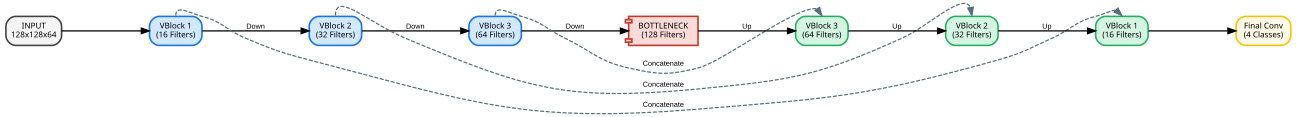

In [8]:
import graphviz
from IPython.display import Image

def draw_vnet3d_horizontal_elegant():
    # Khởi tạo đồ thị nằm ngang (LR)
    dot = graphviz.Digraph('VNet3D_Elegant', comment='Elegant VNet3D Horizontal', format='png')
    
    # Cấu hình thuộc tính tổng thể: Tăng ranksep để các đường cong có không gian
    dot.attr(rankdir='LR', size='18,10', compound='true', nodesep='0.5', ranksep='1.5')
    dot.attr('node', shape='box', style='filled, rounded', fontname='Arial Bold', fontsize='10', penwidth='2')
    dot.attr('edge', fontname='Arial', fontsize='9', penwidth='1.5')

    # Bảng màu chuyên nghiệp
    COLOR_ENC = '#D1E8FF' 
    COLOR_BOT = '#FADBD8' 
    COLOR_DEC = '#D5F5E3' 
    COLOR_SKIP = '#546E7A'

    # --- CÁC KHỐI CHÍNH ---
    dot.node('In', 'INPUT\n128x128x64', fillcolor='#F5F5F5', color='#424242')
    
    # Encoder
    dot.node('E1', 'VBlock 1\n(16 Filters)', fillcolor=COLOR_ENC, color='#1A73E8')
    dot.node('E2', 'VBlock 2\n(32 Filters)', fillcolor=COLOR_ENC, color='#1A73E8')
    dot.node('E3', 'VBlock 3\n(64 Filters)', fillcolor=COLOR_ENC, color='#1A73E8')
    
    # Bottleneck
    dot.node('Bot', 'BOTTLENECK\n(128 Filters)', fillcolor=COLOR_BOT, color='#C0392B', shape='component')
    
    # Decoder
    dot.node('D3', 'VBlock 3\n(64 Filters)', fillcolor=COLOR_DEC, color='#27AE60')
    dot.node('D2', 'VBlock 2\n(32 Filters)', fillcolor=COLOR_DEC, color='#27AE60')
    dot.node('D1', 'VBlock 1\n(16 Filters)', fillcolor=COLOR_DEC, color='#27AE60')
    
    dot.node('Final', 'Final Conv\n(4 Classes)', fillcolor='#FEF9E7', color='#F1C40F')

    # --- LUỒNG CHÍNH (Đường thẳng) ---
    dot.edge('In', 'E1')
    dot.edge('E1', 'E2', label='Down')
    dot.edge('E2', 'E3', label='Down')
    dot.edge('E3', 'Bot', label='Down')
    dot.edge('Bot', 'D3', label='Up')
    dot.edge('D3', 'D2', label='Up')
    dot.edge('D2', 'D1', label='Up')
    dot.edge('D1', 'Final')

    # --- SKIP CONNECTIONS (Uốn cong nghệ thuật) ---
    # Đường nối E3 -> D3 (Ngắn nhất, uốn thấp)
    dot.edge('E3', 'D3', 'Concatenate', style='dashed', color=COLOR_SKIP, 
             constraint='false', tailport='n', headport='n')
    
    # Đường nối E2 -> D2 (Trung bình, uốn cao hơn)
    # Dùng chiều n:nw (north to northwest) để tạo độ vồng khác nhau
    dot.edge('E2', 'D2', 'Concatenate', style='dashed', color=COLOR_SKIP, 
             constraint='false', tailport='n', headport='n')
    
    # Đường nối E1 -> D1 (Dài nhất, uốn cao nhất)
    dot.edge('E1', 'D1', 'Concatenate', style='dashed', color=COLOR_SKIP, 
             constraint='false', tailport='n', headport='n')

    return dot

# Thực thi
vnet_elegant = draw_vnet3d_horizontal_elegant()
vnet_elegant.render('vnet3d_horizontal_elegant')
display(vnet_elegant)

# **Cell: Khôi phục danh sách ảnh Test (te_items)**

In [2]:
from sklearn.model_selection import train_test_split
from pathlib import Path  # Thêm dòng này vào
ROOT_DIR = Path("/kaggle/input/m-and-ms-challenge/MnM2/dataset")
SEED = 42
items = []

for p in sorted(ROOT_DIR.iterdir()):
    if not p.is_dir(): continue
    for s in ["ED", "ES"]:
        img, gt = p/f"{p.name}_SA_{s}.nii", p/f"{p.name}_SA_{s}_gt.nii"
        if img.exists() and gt.exists(): 
            items.append((str(img), str(gt)))

# Split lại y hệt lúc train để lấy đúng danh sách te_items
from sklearn.model_selection import train_test_split
tr_items, temp_items = train_test_split(items, test_size=0.3, random_state=SEED)
va_items, te_items = train_test_split(temp_items, test_size=0.5, random_state=SEED)

print(f"✅ Đã khôi phục danh sách Test: {len(te_items)} mẫu.")

✅ Đã khôi phục danh sách Test: 108 mẫu.


# **Cell: GradCAM từng tầng của từng lớp từng lớp (LV,MYO,RV)**

🔬 Đang trích xuất đặc trưng đa tầng cho mẫu: 82


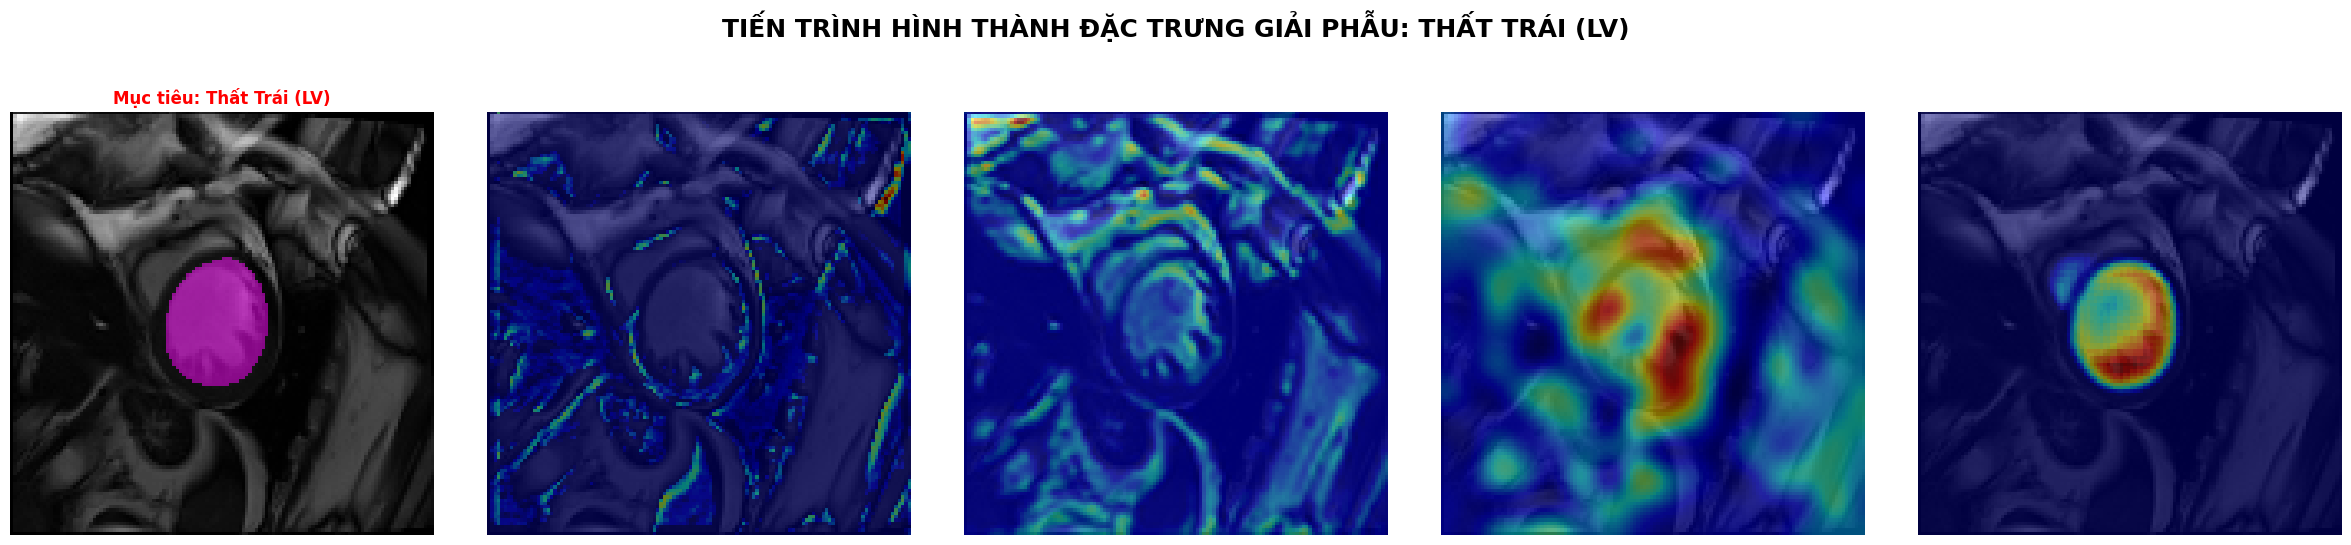

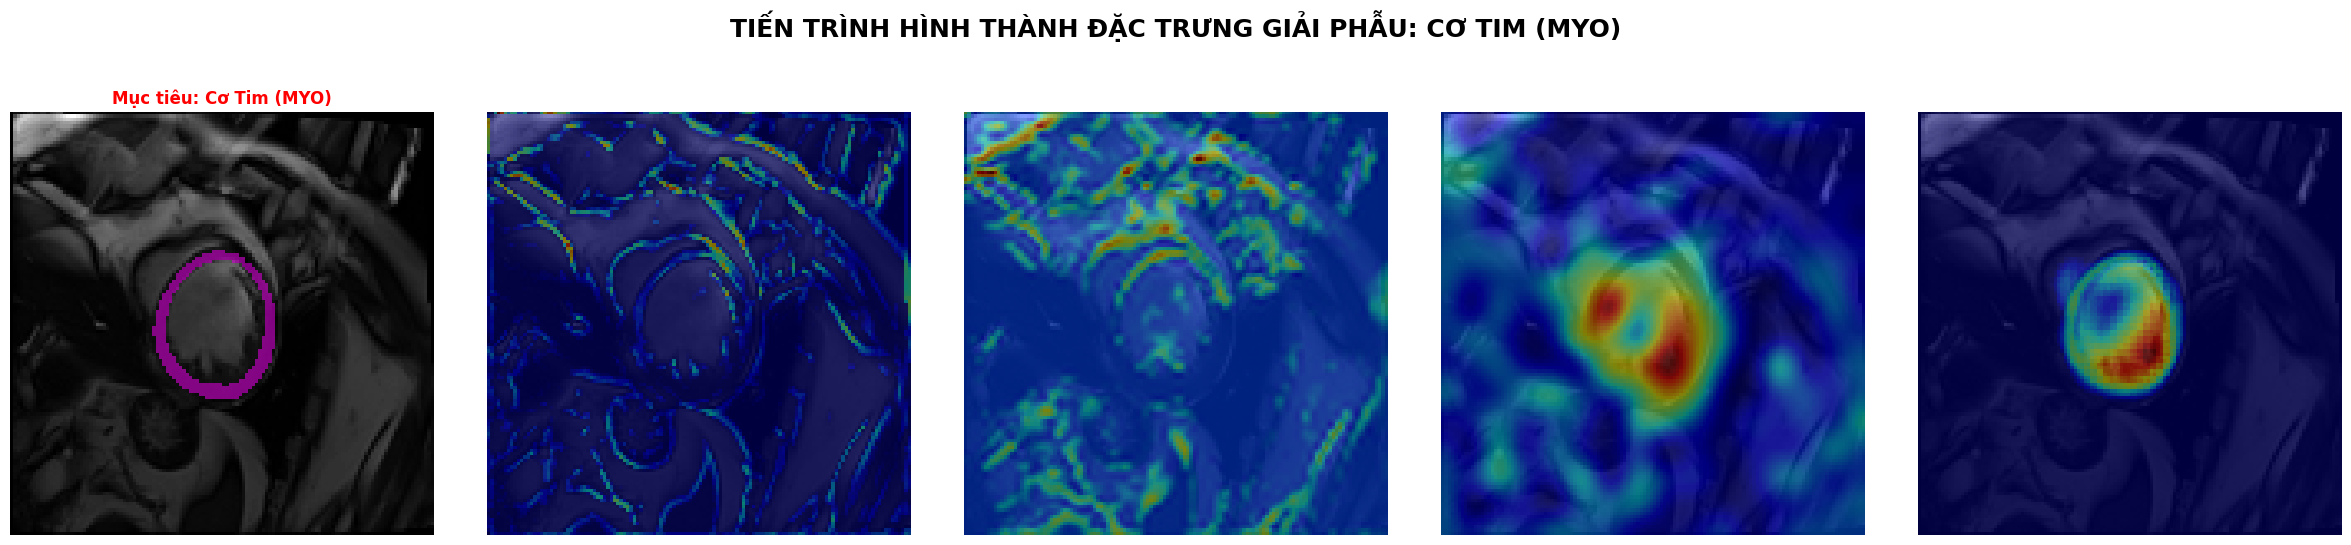

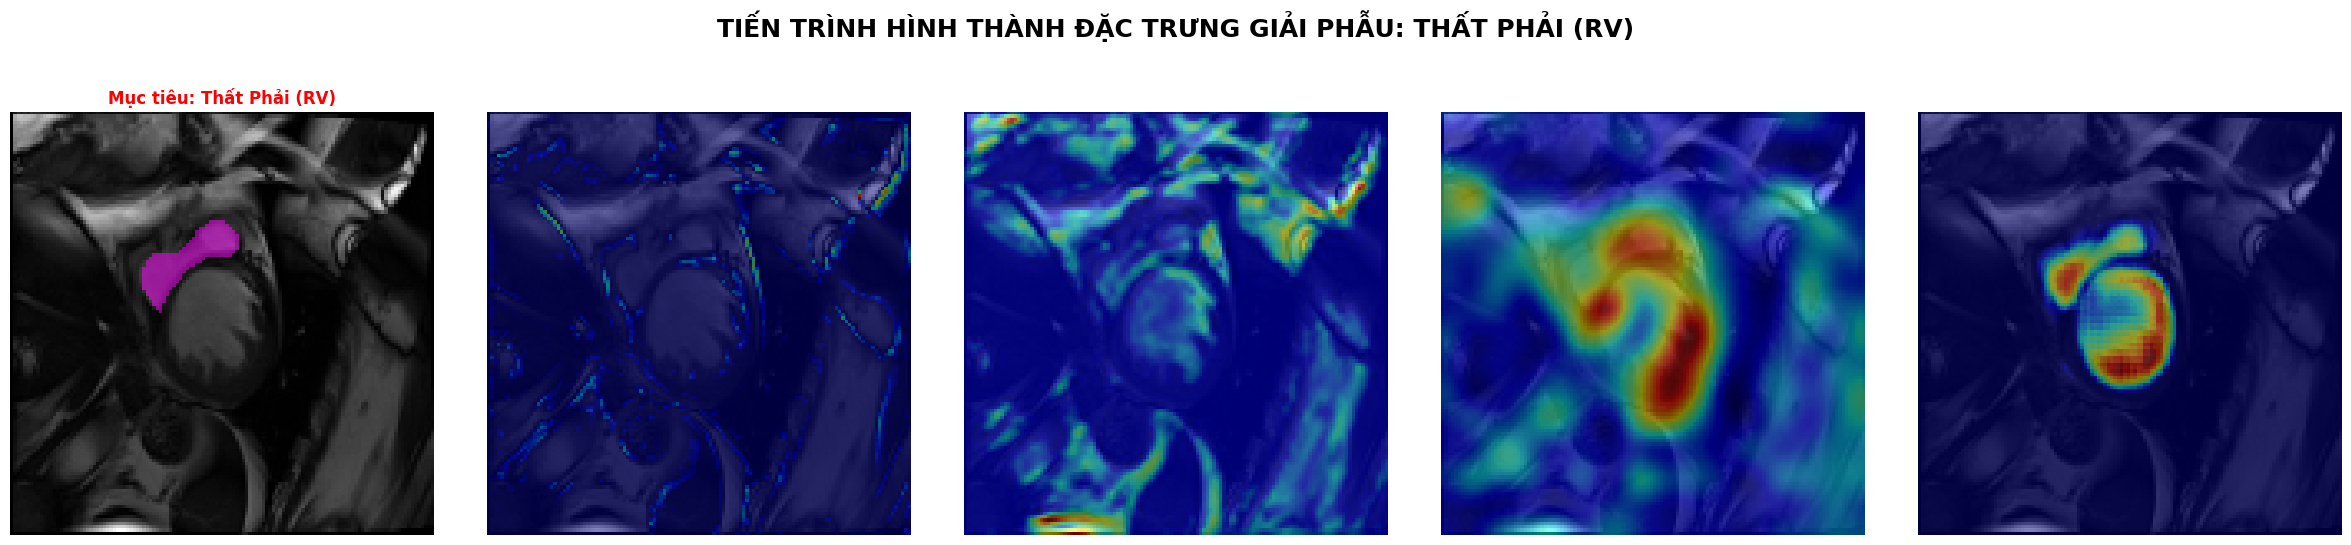

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import nibabel as nib
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

# --- 1. ĐỊNH NGHĨA LẠI KIẾN TRÚC (BẮT BUỘC ĐỂ LOAD MODEL) ---
class ShortCutConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Identity() if in_ch == out_ch else nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, bias=False), nn.InstanceNorm3d(out_ch))
    def forward(self, x): return self.conv(x)

class VBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = nn.Conv3d(in_ch, out_ch, 5, padding=2, bias=False)
        self.in1 = nn.InstanceNorm3d(out_ch); self.prelu1 = nn.PReLU(out_ch)
        self.conv2 = nn.Conv3d(out_ch, out_ch, 5, padding=2, bias=False)
        self.in2 = nn.InstanceNorm3d(out_ch); self.prelu2 = nn.PReLU(out_ch)
        self.short = ShortCutConv3D(in_ch, out_ch)
    def forward(self, x):
        sc = self.short(x)
        out = self.prelu2(self.in2(self.conv2(self.prelu1(self.in1(self.conv1(x))))))
        return out + sc

class VNet3D(nn.Module):
    def __init__(self, num_classes=4, f=16):
        super().__init__()
        self.enc1 = VBlock(1, f); self.down1 = nn.Conv3d(f, 2*f, 2, stride=2) 
        self.enc2 = VBlock(2*f, 2*f); self.down2 = nn.Conv3d(2*f, 4*f, 2, stride=2)
        self.enc3 = VBlock(4*f, 4*f); self.down3 = nn.Conv3d(4*f, 8*f, 2, stride=2)
        self.bottleneck = VBlock(8*f, 8*f)
        self.up3 = nn.ConvTranspose3d(8*f, 8*f, 2, stride=2); self.dec3 = VBlock(12*f, 4*f) 
        self.up2 = nn.ConvTranspose3d(4*f, 4*f, 2, stride=2); self.dec2 = VBlock(6*f, 2*f)  
        self.up1 = nn.ConvTranspose3d(2*f, 2*f, 2, stride=2); self.dec1 = VBlock(3*f, f)    
        self.final = nn.Conv3d(f, num_classes, 1)
    def forward(self, x):
        x1 = self.enc1(x); x2 = self.enc2(self.down1(x1)); x3 = self.enc3(self.down2(x2))
        b = self.bottleneck(self.down3(x3))
        d3 = self.dec3(torch.cat([self.up3(b), x3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), x2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), x1], 1))
        return self.final(d1)

# --- 2. LOAD MODEL ---
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
model = VNet3D(num_classes=4).to(DEVICE)
MODEL_PATH = "/kaggle/input/v-net3d/best_model.pth" 
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

# --- 3. CLASS GRAD-CAM ĐA TẦNG NÂNG CAO ---
class AdvancedGradCAM3D:
    def __init__(self, model, target_layers_dict):
        self.model = model
        self.layers = target_layers_dict
        self.activations = {}
        self.gradients = {}
        self.handles = []
        for name, layer in self.layers.items():
            self.handles.append(layer.register_forward_hook(self._save_act(name)))
            self.handles.append(layer.register_full_backward_hook(self._save_grad(name)))
    def _save_act(self, name): return lambda mod, inp, out: self.activations.update({name: out.detach()})
    def _save_grad(self, name): return lambda mod, gin, gout: self.gradients.update({name: gout[0].detach()})
    
    def generate(self, input_tensor, class_idx, layer_name):
        self.model.zero_grad()
        input_tensor.requires_grad = True
        output = self.model(input_tensor)
        loss = output[0, class_idx].sum()
        loss.backward(retain_graph=True)
        
        grad = self.gradients[layer_name]
        act = self.activations[layer_name]
        weights = torch.mean(grad, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * act, dim=1).squeeze(0)
        cam = F.relu(cam).cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

# Đăng ký các tầng muốn quan sát
target_layers = {
    "Sơ cấp (Enc1)": model.enc1,
    "Trung cấp (Enc2)": model.enc2,
    "Sâu (Bottleneck)": model.bottleneck,
    "Quyết định (Final)": model.final
}
adv_cam = AdvancedGradCAM3D(model, target_layers)

# --- 4. HÀM HIỂN THỊ PHÂN TÍCH SÂU (CẬP NHẬT: THÊM CƠ TIM) ---
def visualize_full_cardiac_xai_layers(sample_idx=None):
    if sample_idx is None: 
        sample_idx = np.random.randint(0, len(te_items)-1)
    
    # Lấy dữ liệu mẫu
    data = VolumeDataset(te_items)[sample_idx]
    img = data['image'].unsqueeze(0).to(DEVICE)
    label = data['label'].numpy()
    img_np = img.detach().cpu().numpy()[0, 0]
    
    # Định nghĩa 3 lớp cần soi: 1: Thất trái, 2: Cơ tim, 3: Thất phải
    classes = {1: "Thất Trái (LV)", 2: "Cơ Tim (MYO)", 3: "Thất Phải (RV)"}
    
    print(f"🔬 Đang trích xuất đặc trưng đa tầng cho mẫu: {sample_idx}")

    for cls_idx, cls_name in classes.items():
        # Tìm lát cắt chứa lớp này nhiều nhất để hiển thị rõ nhất
        slice_idx = np.argmax(np.sum(label == cls_idx, axis=(0, 1)))
        
        plt.figure(figsize=(24, 5))
        
        # Ô 1: Ground Truth (Mục tiêu thực tế)
        plt.subplot(1, len(target_layers) + 1, 1)
        plt.imshow(img_np[:, :, slice_idx], cmap='gray')
        mask = np.ma.masked_where(label[:, :, slice_idx] != cls_idx, label[:, :, slice_idx])
        plt.imshow(mask, cmap='spring', alpha=0.5)
        plt.title(f"Mục tiêu: {cls_name}", fontweight='bold', color='red')
        plt.axis('off')

        # Các ô tiếp theo: Grad-CAM qua các tầng (Enc1 -> Final)
        for i, layer_name in enumerate(target_layers.keys()):
            # Tạo heatmap từ công cụ adv_cam đã định nghĩa ở trên
            heatmap = adv_cam.generate(img, cls_idx, layer_name)
            
            # Khôi phục kích thước heatmap về 128x128x64 để đè lên ảnh gốc
            h_res = zoom(heatmap, (img_np.shape[0]/heatmap.shape[0], 
                                   img_np.shape[1]/heatmap.shape[1], 
                                   img_np.shape[2]/heatmap.shape[2]))
            
            plt.subplot(1, len(target_layers) + 1, i + 2)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            plt.imshow(h_res[:, :, slice_idx], cmap='jet', alpha=0.5)
            plt.axis('off')
        
        plt.suptitle(f"TIẾN TRÌNH HÌNH THÀNH ĐẶC TRƯNG GIẢI PHẪU: {cls_name.upper()}", 
                     fontsize=18, y=1.08, fontweight='bold')
        plt.tight_layout()
        plt.show()

# Thực thi phân tích cho toàn bộ cấu trúc tim
visualize_full_cardiac_xai_layers()

🔬 Đang trích xuất đặc trưng đa tầng cho mẫu: 27


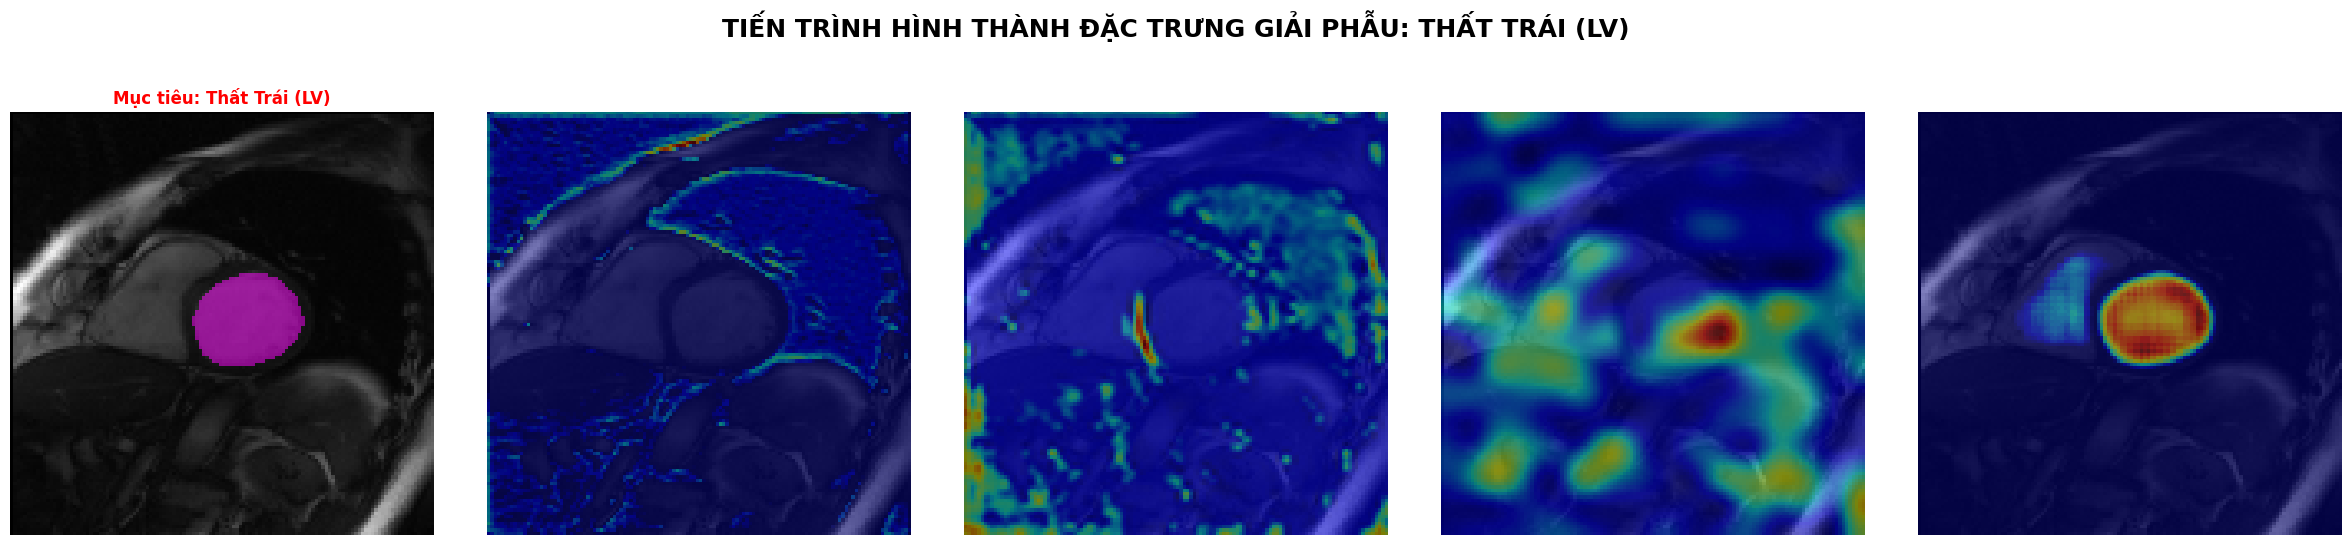

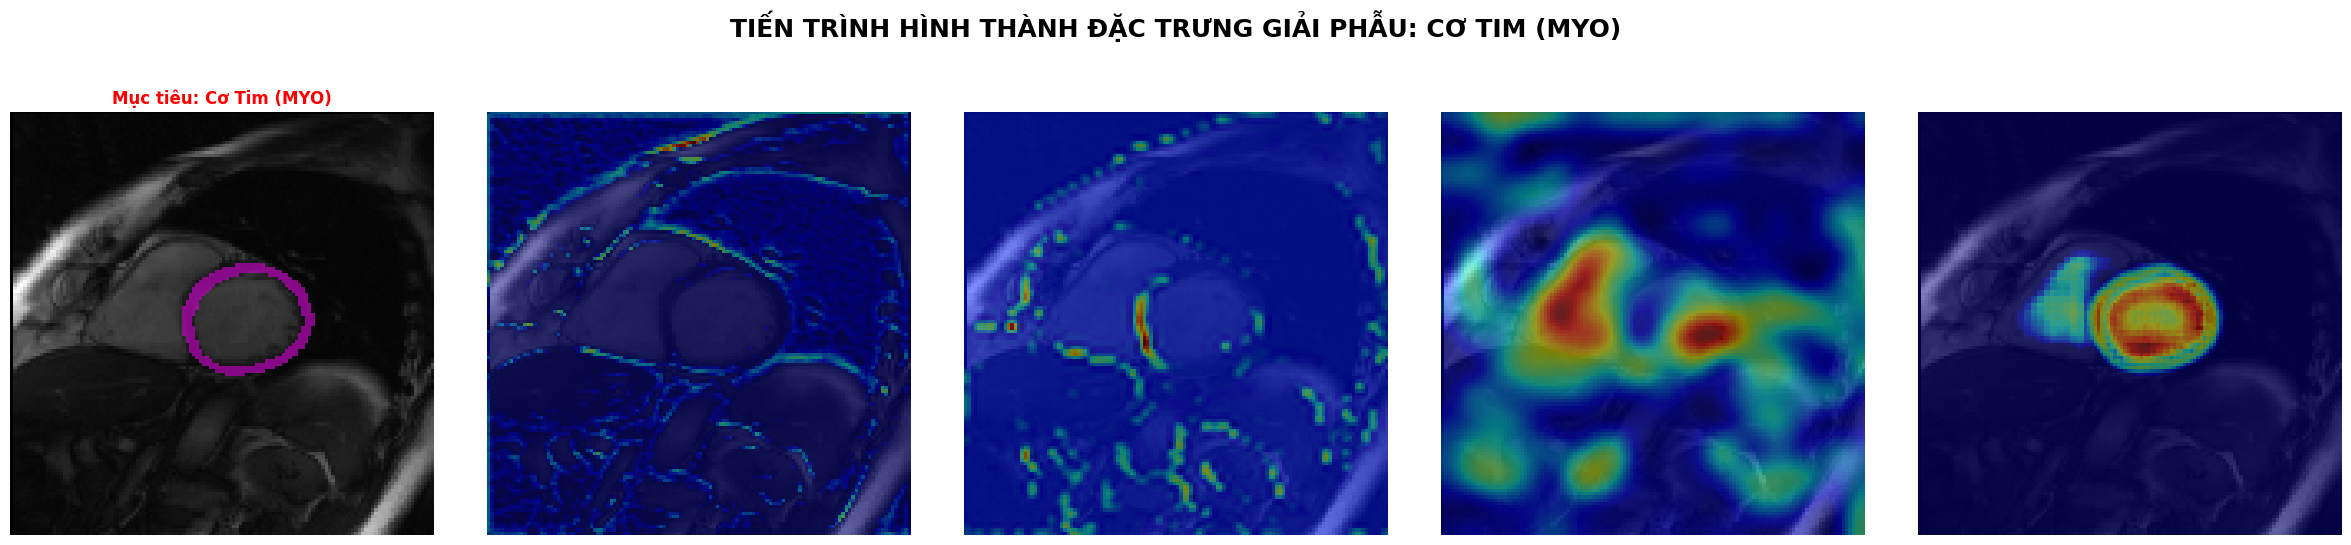

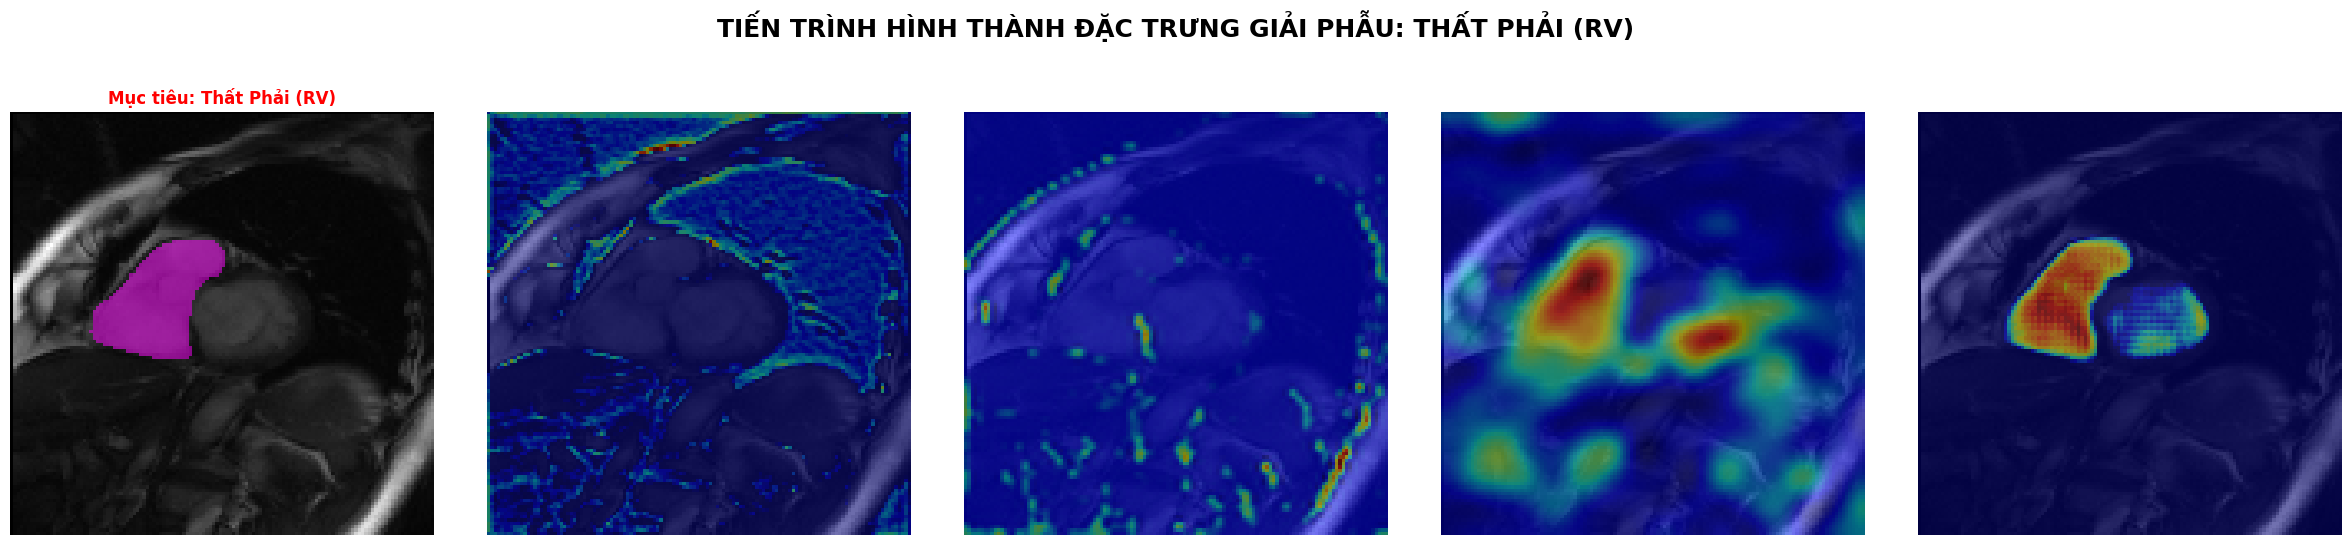

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import nibabel as nib
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

# --- 1. ĐỊNH NGHĨA LẠI KIẾN TRÚC (BẮT BUỘC ĐỂ LOAD MODEL) ---
class ShortCutConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Identity() if in_ch == out_ch else nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 1, bias=False), nn.InstanceNorm3d(out_ch))
    def forward(self, x): return self.conv(x)

class VBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = nn.Conv3d(in_ch, out_ch, 5, padding=2, bias=False)
        self.in1 = nn.InstanceNorm3d(out_ch); self.prelu1 = nn.PReLU(out_ch)
        self.conv2 = nn.Conv3d(out_ch, out_ch, 5, padding=2, bias=False)
        self.in2 = nn.InstanceNorm3d(out_ch); self.prelu2 = nn.PReLU(out_ch)
        self.short = ShortCutConv3D(in_ch, out_ch)
    def forward(self, x):
        sc = self.short(x)
        out = self.prelu2(self.in2(self.conv2(self.prelu1(self.in1(self.conv1(x))))))
        return out + sc

class VNet3D(nn.Module):
    def __init__(self, num_classes=4, f=16):
        super().__init__()
        self.enc1 = VBlock(1, f); self.down1 = nn.Conv3d(f, 2*f, 2, stride=2) 
        self.enc2 = VBlock(2*f, 2*f); self.down2 = nn.Conv3d(2*f, 4*f, 2, stride=2)
        self.enc3 = VBlock(4*f, 4*f); self.down3 = nn.Conv3d(4*f, 8*f, 2, stride=2)
        self.bottleneck = VBlock(8*f, 8*f)
        self.up3 = nn.ConvTranspose3d(8*f, 8*f, 2, stride=2); self.dec3 = VBlock(12*f, 4*f) 
        self.up2 = nn.ConvTranspose3d(4*f, 4*f, 2, stride=2); self.dec2 = VBlock(6*f, 2*f)  
        self.up1 = nn.ConvTranspose3d(2*f, 2*f, 2, stride=2); self.dec1 = VBlock(3*f, f)    
        self.final = nn.Conv3d(f, num_classes, 1)
    def forward(self, x):
        x1 = self.enc1(x); x2 = self.enc2(self.down1(x1)); x3 = self.enc3(self.down2(x2))
        b = self.bottleneck(self.down3(x3))
        d3 = self.dec3(torch.cat([self.up3(b), x3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), x2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), x1], 1))
        return self.final(d1)

# --- 2. LOAD MODEL ---
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
model = VNet3D(num_classes=4).to(DEVICE)
MODEL_PATH = "/kaggle/input/v-net3d/best_model.pth" 
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

# --- 3. CLASS GRAD-CAM ĐA TẦNG NÂNG CAO ---
class AdvancedGradCAM3D:
    def __init__(self, model, target_layers_dict):
        self.model = model
        self.layers = target_layers_dict
        self.activations = {}
        self.gradients = {}
        self.handles = []
        for name, layer in self.layers.items():
            self.handles.append(layer.register_forward_hook(self._save_act(name)))
            self.handles.append(layer.register_full_backward_hook(self._save_grad(name)))
    def _save_act(self, name): return lambda mod, inp, out: self.activations.update({name: out.detach()})
    def _save_grad(self, name): return lambda mod, gin, gout: self.gradients.update({name: gout[0].detach()})
    
    def generate(self, input_tensor, class_idx, layer_name):
        self.model.zero_grad()
        input_tensor.requires_grad = True
        output = self.model(input_tensor)
        loss = output[0, class_idx].sum()
        loss.backward(retain_graph=True)
        
        grad = self.gradients[layer_name]
        act = self.activations[layer_name]
        weights = torch.mean(grad, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * act, dim=1).squeeze(0)
        cam = F.relu(cam).cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

# Đăng ký các tầng muốn quan sát
target_layers = {
    "Sơ cấp (Enc1)": model.enc1,
    "Trung cấp (Enc2)": model.enc2,
    "Sâu (Bottleneck)": model.bottleneck,
    "Quyết định (Final)": model.final
}
adv_cam = AdvancedGradCAM3D(model, target_layers)

# --- 4. HÀM HIỂN THỊ PHÂN TÍCH SÂU (CẬP NHẬT: THÊM CƠ TIM) ---
def visualize_full_cardiac_xai_layers(sample_idx=None):
    if sample_idx is None: 
        sample_idx = np.random.randint(0, len(te_items)-1)
    
    # Lấy dữ liệu mẫu
    data = VolumeDataset(te_items)[sample_idx]
    img = data['image'].unsqueeze(0).to(DEVICE)
    label = data['label'].numpy()
    img_np = img.detach().cpu().numpy()[0, 0]
    
    # Định nghĩa 3 lớp cần soi: 1: Thất trái, 2: Cơ tim, 3: Thất phải
    classes = {1: "Thất Trái (LV)", 2: "Cơ Tim (MYO)", 3: "Thất Phải (RV)"}
    
    print(f"🔬 Đang trích xuất đặc trưng đa tầng cho mẫu: {sample_idx}")

    for cls_idx, cls_name in classes.items():
        # Tìm lát cắt chứa lớp này nhiều nhất để hiển thị rõ nhất
        slice_idx = np.argmax(np.sum(label == cls_idx, axis=(0, 1)))
        
        plt.figure(figsize=(24, 5))
        
        # Ô 1: Ground Truth (Mục tiêu thực tế)
        plt.subplot(1, len(target_layers) + 1, 1)
        plt.imshow(img_np[:, :, slice_idx], cmap='gray')
        mask = np.ma.masked_where(label[:, :, slice_idx] != cls_idx, label[:, :, slice_idx])
        plt.imshow(mask, cmap='spring', alpha=0.5)
        plt.title(f"Mục tiêu: {cls_name}", fontweight='bold', color='red')
        plt.axis('off')

        # Các ô tiếp theo: Grad-CAM qua các tầng (Enc1 -> Final)
        for i, layer_name in enumerate(target_layers.keys()):
            # Tạo heatmap từ công cụ adv_cam đã định nghĩa ở trên
            heatmap = adv_cam.generate(img, cls_idx, layer_name)
            
            # Khôi phục kích thước heatmap về 128x128x64 để đè lên ảnh gốc
            h_res = zoom(heatmap, (img_np.shape[0]/heatmap.shape[0], 
                                   img_np.shape[1]/heatmap.shape[1], 
                                   img_np.shape[2]/heatmap.shape[2]))
            
            plt.subplot(1, len(target_layers) + 1, i + 2)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            plt.imshow(h_res[:, :, slice_idx], cmap='jet', alpha=0.5)
            plt.axis('off')
        
        plt.suptitle(f"TIẾN TRÌNH HÌNH THÀNH ĐẶC TRƯNG GIẢI PHẪU: {cls_name.upper()}", 
                     fontsize=18, y=1.08, fontweight='bold')
        plt.tight_layout()
        plt.show()

# Thực thi phân tích cho toàn bộ cấu trúc tim
visualize_full_cardiac_xai_layers()

# **Cell: GradCAM từng tầng cho cả 3 lớp**

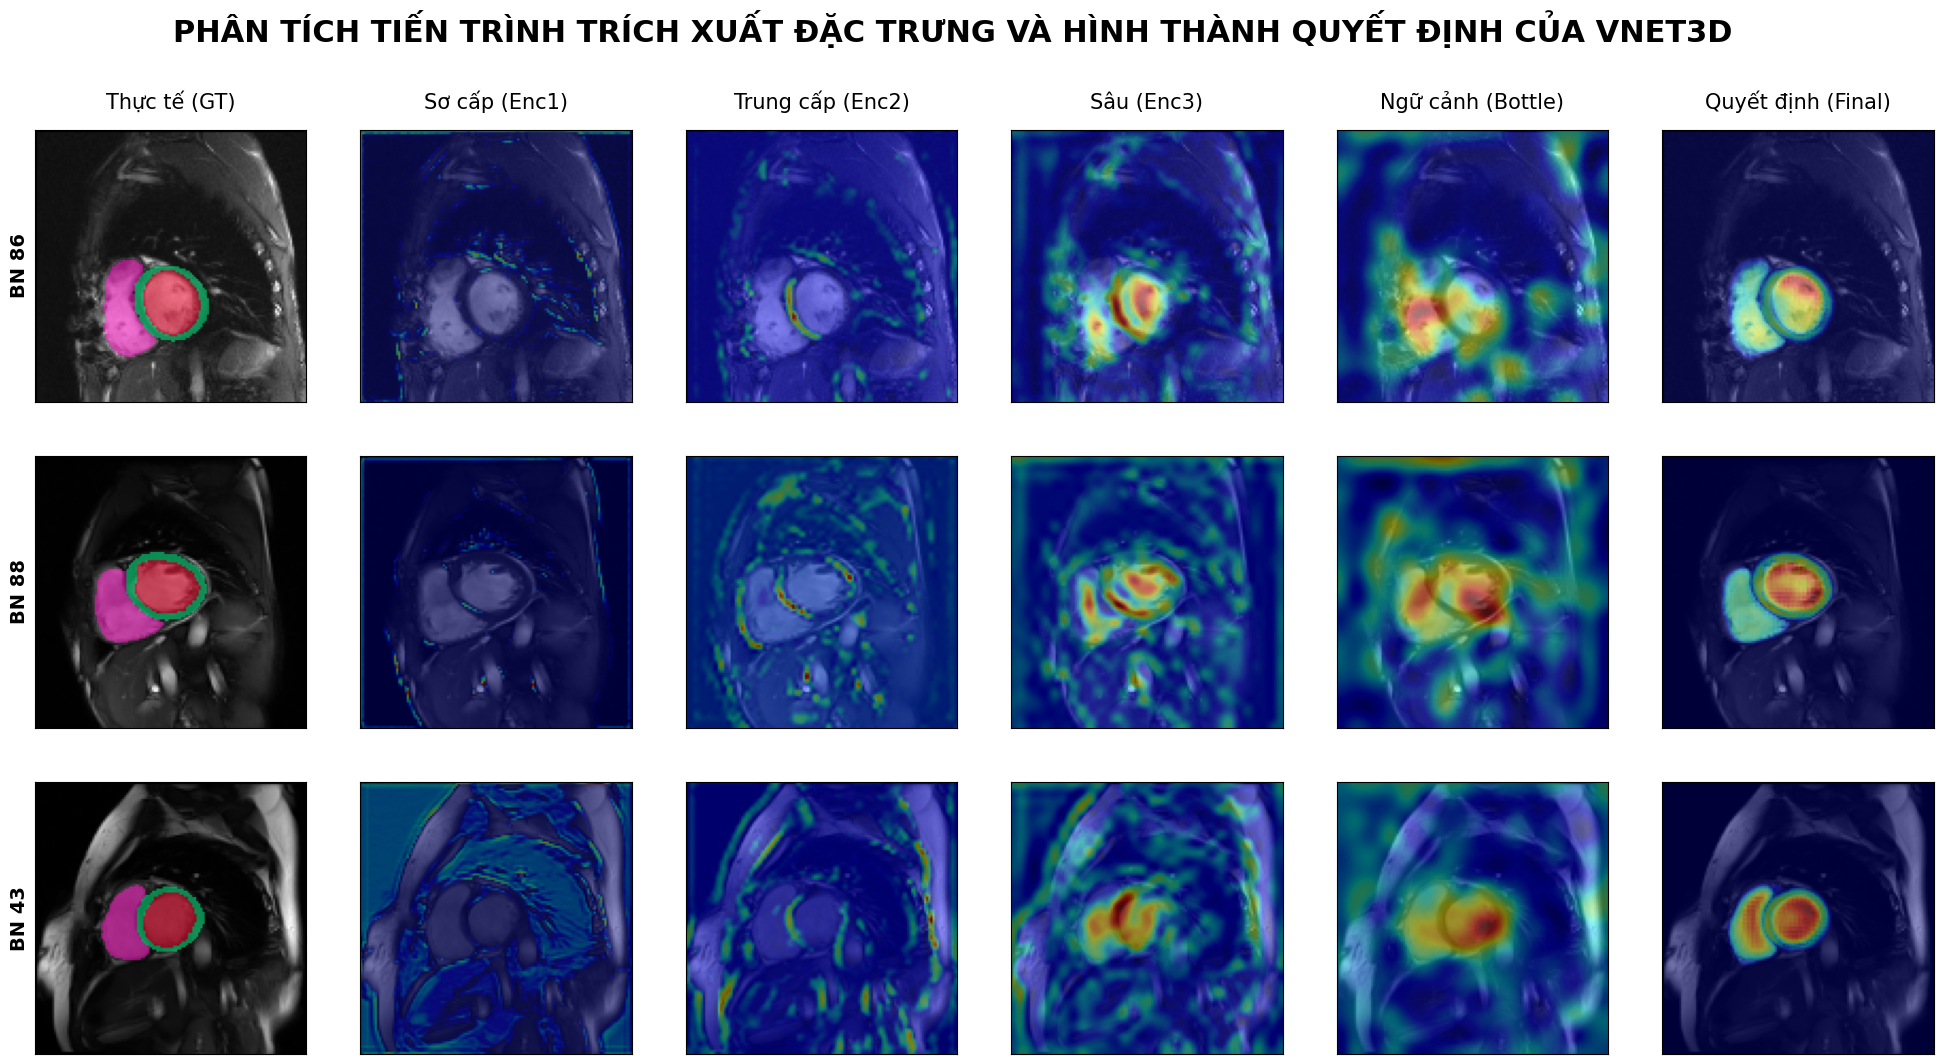

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.ndimage import zoom

# --- 1. ĐỊNH NGHĨA LẠI CÔNG CỤ GRAD-CAM NÂNG CAO ---
class AdvancedGradCAM3D:
    def __init__(self, model, target_layers_dict):
        self.model = model
        self.layers = target_layers_dict
        self.activations = {}
        self.gradients = {}
        self.handles = []
        for name, layer in self.layers.items():
            self.handles.append(layer.register_forward_hook(self._save_act(name)))
            self.handles.append(layer.register_full_backward_hook(self._save_grad(name)))
    
    def _save_act(self, name): 
        return lambda mod, inp, out: self.activations.update({name: out.detach()})
    
    def _save_grad(self, name): 
        return lambda mod, gin, gout: self.gradients.update({name: gout[0].detach()})
    
    def generate(self, input_tensor, class_idx, layer_name):
        self.model.zero_grad()
        input_tensor.requires_grad = True
        output = self.model(input_tensor)
        loss = output[0, class_idx].sum()
        loss.backward(retain_graph=True)
        
        grad = self.gradients[layer_name]
        act = self.activations[layer_name]
        weights = torch.mean(grad, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * act, dim=1).squeeze(0)
        cam = F.relu(cam).cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    def remove_hooks(self):
        for h in self.handles: h.remove()

# --- 2. KHỞI TẠO ĐỐI TƯỢNG XAI ---
target_layers = {
    "Sơ cấp (Enc1)": model.enc1,
    "Trung cấp (Enc2)": model.enc2,
    "Sâu (Enc3)": model.enc3,
    "Ngữ cảnh (Bottle)": model.bottleneck,
    "Quyết định (Final)": model.final
}
adv_cam = AdvancedGradCAM3D(model, target_layers)

# --- 3. HÀM HIỂN THỊ DASHBOARD 3 BỆNH NHÂN ---
def visualize_triple_patient_evolution_full():
    model.eval()
    # Chọn ngẫu nhiên 3 bệnh nhân từ tập Test
    sample_indices = random.sample(range(len(te_items)), 3)
    num_cols = len(target_layers) + 1 # +1 cho cột Ground Truth
    
    fig, axes = plt.subplots(3, num_cols, figsize=(25, 12))
    plt.subplots_adjust(wspace=0.05, hspace=0.2)

    for row_idx, sample_idx in enumerate(sample_indices):
        # Load dữ liệu bệnh nhân
        data = VolumeDataset(te_items)[sample_idx]
        img = data['image'].unsqueeze(0).to(DEVICE)
        label = data['label'].numpy()
        img_np = img.detach().cpu().numpy()[0, 0]
        
        # Tìm lát cắt có tim rõ nhất (tổng hợp 3 lớp)
        slice_idx = np.argmax(np.sum(label > 0, axis=(0, 1)))

        # --- CỘT 1: GROUND TRUTH TỔNG HỢP ---
        ax_gt = axes[row_idx, 0]
        ax_gt.imshow(img_np[:, :, slice_idx], cmap='gray')
        # Mask hiển thị 3 vùng màu khác nhau
        mask_all = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
        ax_gt.imshow(mask_all, cmap='gist_rainbow', alpha=0.5)
        ax_gt.set_ylabel(f"BN {sample_idx}", fontsize=14, fontweight='bold')
        if row_idx == 0: ax_gt.set_title("Thực tế (GT)", fontsize=15, pad=15)
        ax_gt.set_xticks([]); ax_gt.set_yticks([])

        # --- CÁC CỘT TIẾP THEO: XAI TIẾN HÓA ---
        for col_idx, (layer_name, layer_obj) in enumerate(target_layers.items()):
            # Cộng dồn sự chú ý của cả 3 lớp LV(1), MYO(2), RV(3)
            combined_heatmap = None
            for cls_idx in [1, 2, 3]:
                h = adv_cam.generate(img, cls_idx, layer_name)
                if combined_heatmap is None: combined_heatmap = h
                else: combined_heatmap = np.maximum(combined_heatmap, h) # Lấy vùng chú ý mạnh nhất
            
            # Resize về kích thước ảnh gốc
            h_res = zoom(combined_heatmap, (img_np.shape[0]/combined_heatmap.shape[0], 
                                            img_np.shape[1]/combined_heatmap.shape[1], 
                                            img_np.shape[2]/combined_heatmap.shape[2]))
            
            ax_xai = axes[row_idx, col_idx + 1]
            ax_xai.imshow(img_np[:, :, slice_idx], cmap='gray')
            ax_xai.imshow(h_res[:, :, slice_idx], cmap='jet', alpha=0.45)
            
            if row_idx == 0: 
                ax_xai.set_title(layer_name, fontsize=15, pad=15)
            ax_xai.set_xticks([]); ax_xai.set_yticks([])

    plt.suptitle("PHÂN TÍCH TIẾN TRÌNH TRÍCH XUẤT ĐẶC TRƯNG VÀ HÌNH THÀNH QUYẾT ĐỊNH CỦA VNET3D", 
                 fontsize=22, y=0.98, fontweight='bold')
    plt.show()

# Thực thi
visualize_triple_patient_evolution_full()

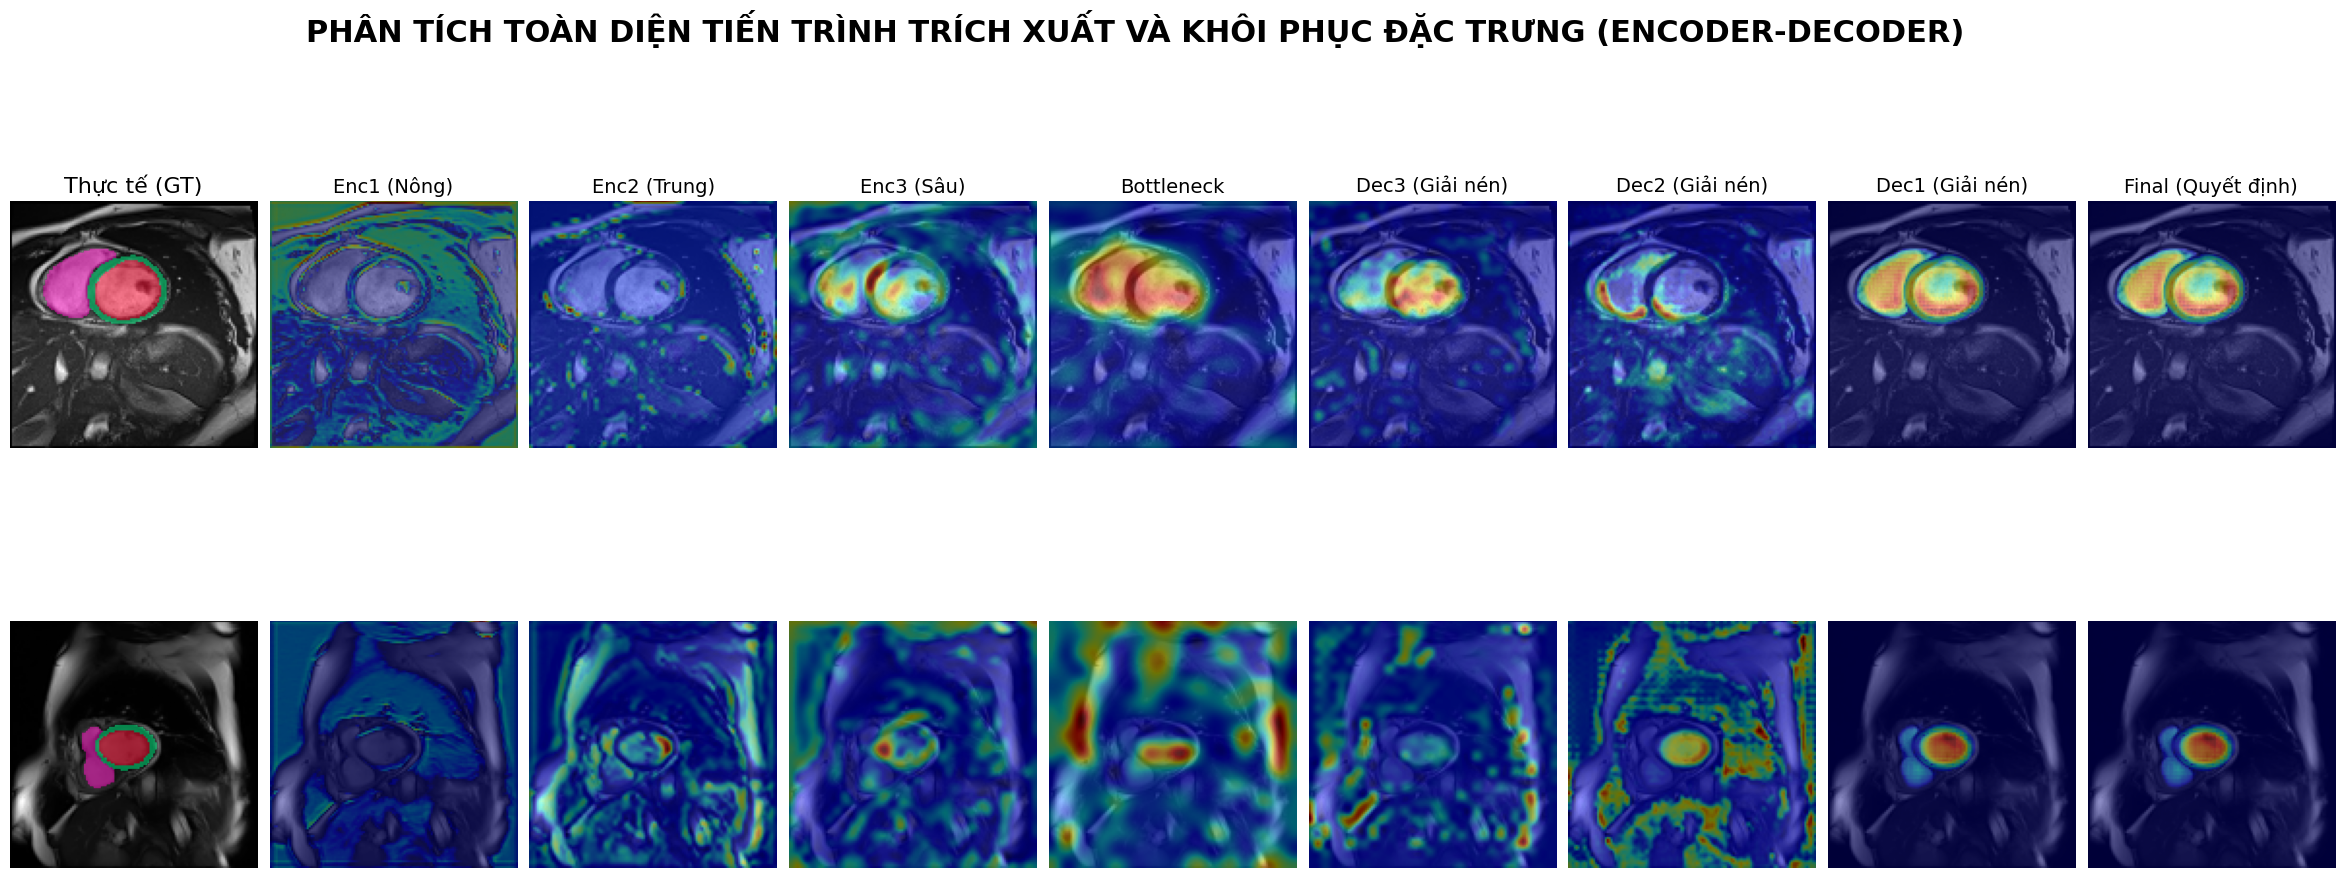

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.ndimage import zoom

# ========================================================================
# 1. ĐỊNH NGHĨA CLASS XAI (PHẢI CÓ TRƯỚC KHI GỌI)
# ========================================================================
class AdvancedGradCAM3D:
    def __init__(self, model, target_layers_dict):
        self.model = model
        self.layers = target_layers_dict
        self.activations = {}
        self.gradients = {}
        self.handles = []
        for name, layer in self.layers.items():
            self.handles.append(layer.register_forward_hook(self._save_act(name)))
            self.handles.append(layer.register_full_backward_hook(self._save_grad(name)))
    
    def _save_act(self, name): 
        return lambda mod, inp, out: self.activations.update({name: out.detach()})
    
    def _save_grad(self, name): 
        return lambda mod, gin, gout: self.gradients.update({name: gout[0].detach()})
    
    def generate(self, input_tensor, class_idx, layer_name):
        self.model.zero_grad()
        input_tensor.requires_grad = True
        output = self.model(input_tensor)
        loss = output[0, class_idx].sum()
        loss.backward(retain_graph=True)
        
        grad = self.gradients[layer_name]
        act = self.activations[layer_name]
        weights = torch.mean(grad, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * act, dim=1).squeeze(0)
        cam = F.relu(cam).cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    def remove_hooks(self):
        for h in self.handles: h.remove()

# ========================================================================
# 2. CẤU HÌNH CÁC TẦNG MỤC TIÊU (DỰA TRÊN CLASS VNet3D CỦA BẠN)
# ========================================================================
# Lưu ý: Các tên biến model.enc1, model.dec1... phải khớp chính xác với class VNet3D
target_layers = {
    "Enc1 (Nông)": model.enc1,
    "Enc2 (Trung)": model.enc2,
    "Enc3 (Sâu)": model.enc3,
    "Bottleneck": model.bottleneck,
    "Dec3 (Giải nén)": model.dec3,
    "Dec2 (Giải nén)": model.dec2,
    "Dec1 (Giải nén)": model.dec1,
    "Final (Quyết định)": model.final
}

adv_cam = AdvancedGradCAM3D(model, target_layers)

# ========================================================================
# 3. HÀM HIỂN THỊ DASHBOARD FULL TIẾN TRÌNH
# ========================================================================
def visualize_full_vnet_flow(num_samples=2):
    model.eval()
    sample_indices = random.sample(range(len(te_items)), num_samples)
    num_cols = len(target_layers) + 1 
    
    fig, axes = plt.subplots(num_samples, num_cols, figsize=(30, 10))
    plt.subplots_adjust(wspace=0.05, hspace=0.2)

    for row_idx, sample_idx in enumerate(sample_indices):
        # Load data
        data = VolumeDataset(te_items)[sample_idx]
        img = data['image'].unsqueeze(0).to(DEVICE)
        label = data['label'].numpy()
        img_np = img.detach().cpu().numpy()[0, 0]
        
        # Lấy lát cắt giữa tim
        slice_idx = np.argmax(np.sum(label > 0, axis=(0, 1)))

        # Cột 1: Thực tế (Ground Truth)
        ax_gt = axes[row_idx, 0]
        ax_gt.imshow(img_np[:, :, slice_idx], cmap='gray')
        mask_all = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
        ax_gt.imshow(mask_all, cmap='gist_rainbow', alpha=0.5)
        ax_gt.set_ylabel(f"BN {sample_idx}", fontsize=14, fontweight='bold')
        if row_idx == 0: ax_gt.set_title("Thực tế (GT)", fontsize=16)
        ax_gt.axis('off')

        # Các cột XAI diễn tiến qua các tầng
        for col_idx, (layer_name, _) in enumerate(target_layers.items()):
            combined_heatmap = None
            # Gộp chú ý của 3 lớp: LV(1), RV(2), MYO(3)
            for cls_idx in [1, 2, 3]:
                try:
                    h = adv_cam.generate(img, cls_idx, layer_name)
                    if combined_heatmap is None: combined_heatmap = h
                    else: combined_heatmap = np.maximum(combined_heatmap, h)
                except: continue
            
            if combined_heatmap is not None:
                # Phóng đại heatmap về kích thước gốc để đè lên ảnh MRI
                h_res = zoom(combined_heatmap, (img_np.shape[0]/combined_heatmap.shape[0], 
                                                img_np.shape[1]/combined_heatmap.shape[1], 
                                                img_np.shape[2]/combined_heatmap.shape[2]))
                
                ax_xai = axes[row_idx, col_idx + 1]
                ax_xai.imshow(img_np[:, :, slice_idx], cmap='gray')
                ax_xai.imshow(h_res[:, :, slice_idx], cmap='jet', alpha=0.45)
                
                if row_idx == 0: ax_xai.set_title(layer_name, fontsize=14)
                ax_xai.axis('off')

    plt.suptitle("PHÂN TÍCH TOÀN DIỆN TIẾN TRÌNH TRÍCH XUẤT VÀ KHÔI PHỤC ĐẶC TRƯNG (ENCODER-DECODER)", 
                 fontsize=22, y=1.02, fontweight='bold')
    plt.show()

# Thực thi
visualize_full_vnet_flow()

# **Cell: Uncertainty XAI**

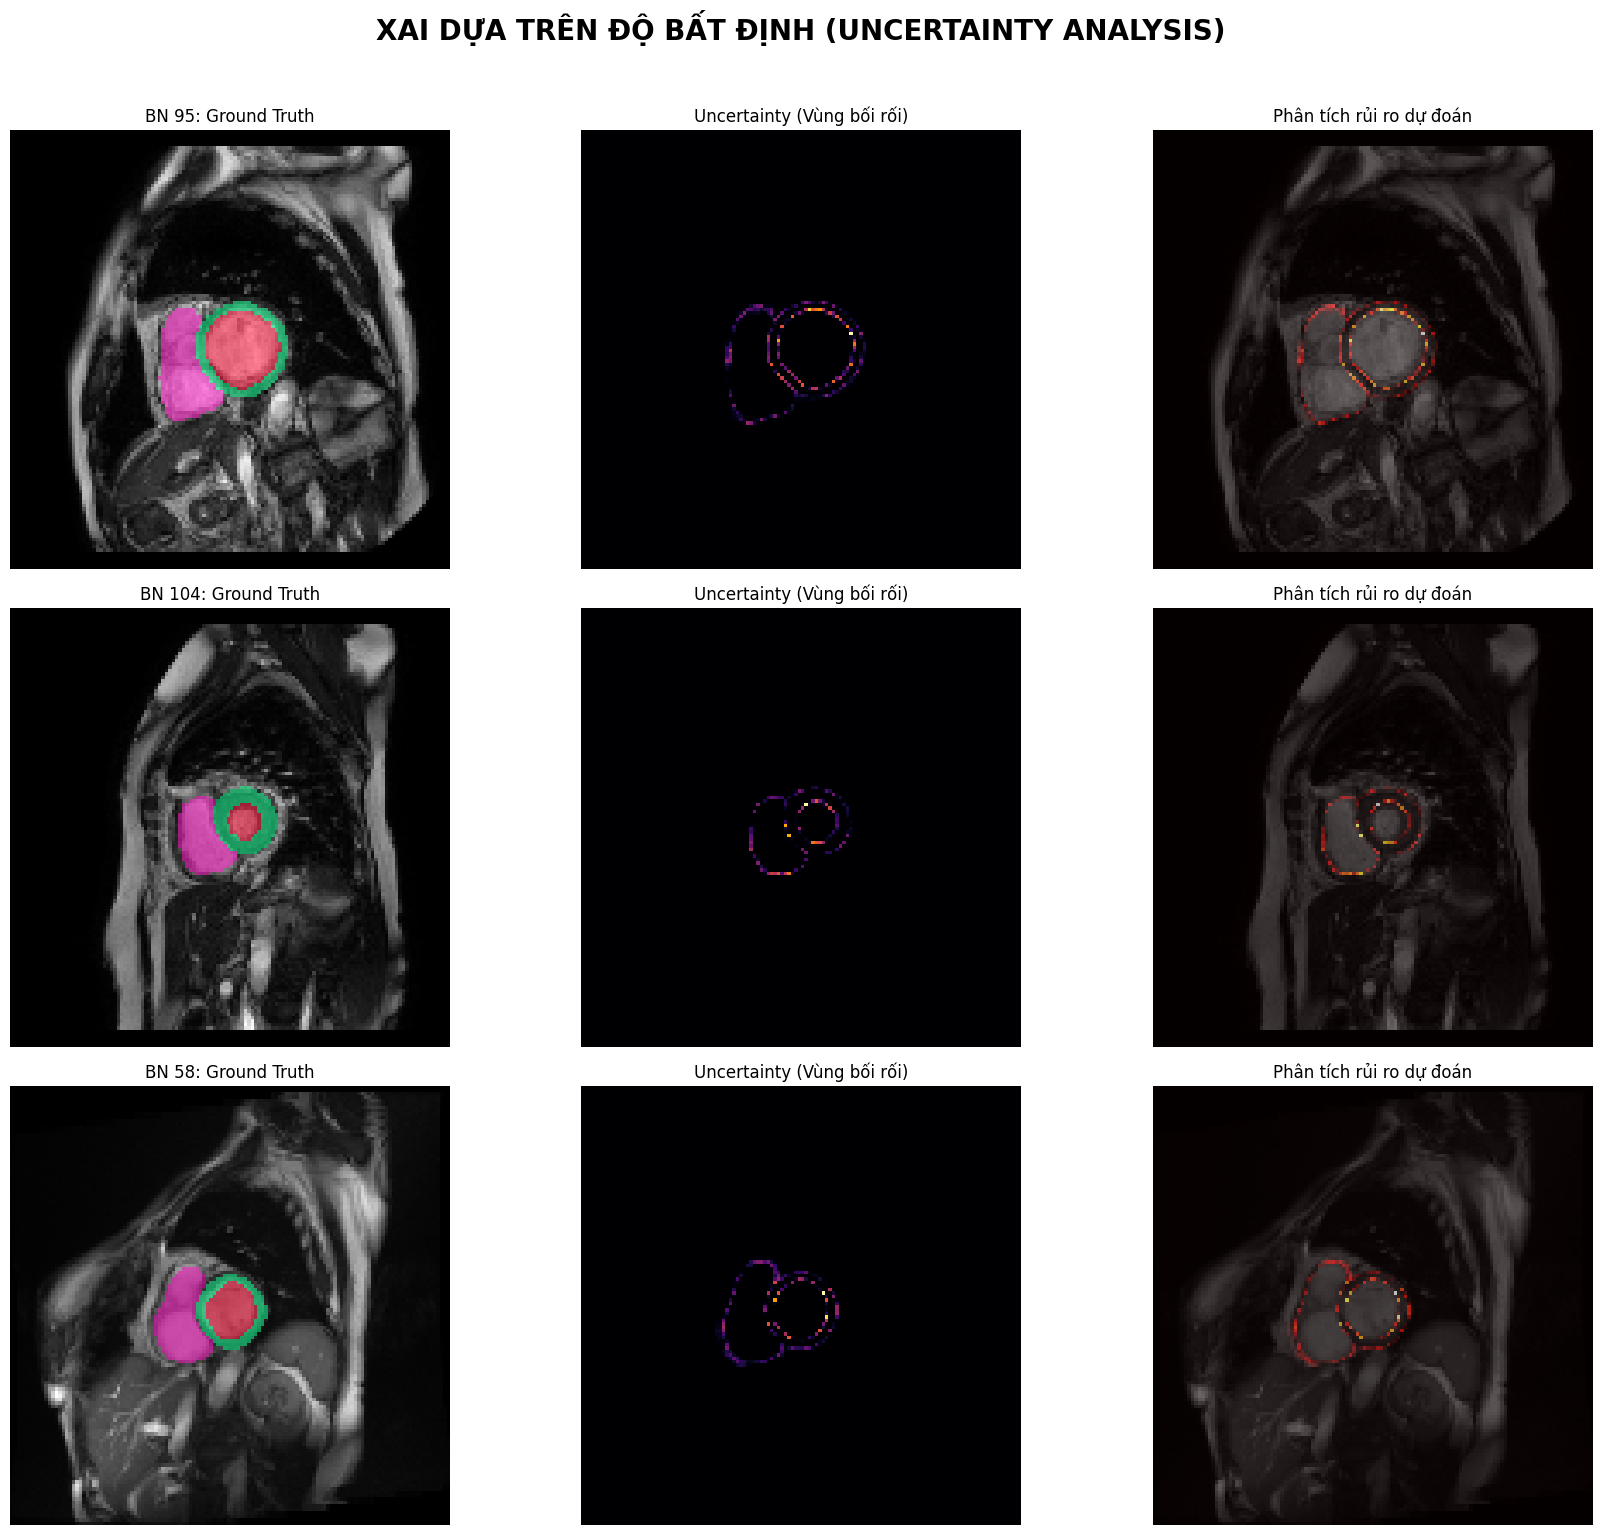

In [42]:
def visualize_uncertainty_xai_3_samples(num_samples=3, iterations=10):
    # CHÚ Ý: Chế độ .train() để kích hoạt Dropout nếu kiến trúc có dùng 
    # Nếu không có Dropout, ta có thể dùng nhiễu nhẹ (Augmentation)
    model.train() 
    torch.cuda.empty_cache()
    
    sample_indices = random.sample(range(len(te_items)), num_samples)
    fig, axes = plt.subplots(num_samples, 3, figsize=(18, 5 * num_samples))

    for i, idx in enumerate(sample_indices):
        data = VolumeDataset(te_items)[idx]
        img = data['image'].unsqueeze(0).to(DEVICE)
        label = data['label'].numpy()
        img_np = img.detach().cpu().numpy()[0, 0]
        slice_idx = np.argmax(np.sum(label > 0, axis=(0, 1)))

        # Chạy mô hình nhiều lần để đo sự biến động (Stochastic Forward Passes)
        outputs = []
        with torch.no_grad():
            for _ in range(iterations):
                # Thêm một chút nhiễu nhẹ vào ảnh để kích thích sự bất định
                noisy_img = img + torch.randn_like(img) * 0.01 
                out = F.softmax(model(noisy_img), dim=1)
                outputs.append(out.cpu().numpy())
        
        # Tính độ lệch chuẩn (Standard Deviation) giữa các lần chạy
        outputs = np.array(outputs) # [iterations, 1, classes, 128, 128, 64]
        uncertainty = np.std(outputs, axis=0)[0, 1:4].sum(axis=0) # Tổng SD của 3 lớp tim
        uncertainty_slice = uncertainty[:, :, slice_idx]
        
        # Chuẩn hóa
        uncertainty_slice = (uncertainty_slice - uncertainty_slice.min()) / (uncertainty_slice.max() - uncertainty_slice.min() + 1e-8)

        # HIỂN THỊ
        # Ô 1: Thực tế
        axes[i, 0].imshow(img_np[:, :, slice_idx], cmap='gray')
        mask = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
        axes[i, 0].imshow(mask, cmap='gist_rainbow', alpha=0.5)
        axes[i, 0].set_title(f"BN {idx}: Ground Truth")
        axes[i, 0].axis('off')

        # Ô 2: Uncertainty Map (Vùng AI bối rối)
        # Vùng màu đỏ càng đậm nghĩa là AI càng không chắc chắn
        im = axes[i, 1].imshow(uncertainty_slice, cmap='inferno')
        axes[i, 1].set_title("Uncertainty (Vùng bối rối)")
        axes[i, 1].axis('off')

        # Ô 3: Kết hợp (MRI + Uncertainty)
        axes[i, 2].imshow(img_np[:, :, slice_idx], cmap='gray')
        axes[i, 2].imshow(uncertainty_slice, cmap='hot', alpha=0.6)
        axes[i, 2].set_title("Phân tích rủi ro dự đoán")
        axes[i, 2].axis('off')

    plt.suptitle("XAI DỰA TRÊN ĐỘ BẤT ĐỊNH (UNCERTAINTY ANALYSIS)", 
                 fontsize=20, y=1.02, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Thực thi
visualize_uncertainty_xai_3_samples()